In [7]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Handling Imbalanced Data
from imblearn.over_sampling import SMOTE

# Explainable AI
import shap

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)

### Load Dataset

In [8]:
df = pd.read_excel("solar_data.xlsx")
df.head()

,customer_id,tenure,total_amount_paid,outstanding_balance,repayment_rate,missed_payments,gender,birth_year,age,payment_3m,avg_payment_3m,payment_trend_3m,volatility_3m,last_paid_month,last_paid_amount,total_calls,outbound_calls,received_calls,unanswered_calls,ivr_calls,csat_calls,total_talk_minutes,repossession_tickets,followup_tickets,complaint_tickets,churn
0,GBEFDJG,1413,426800,365200,54,470,male,1992,33,39600.0,5657.142857,400.0,139.970842,2023-04-01,5600.0,497,30,1,1,2,0,20.75,0.0,0,0,1
1,GBAGFBB,1398,610045,181955,77,253,male,1968,57,53000.0,5300.000000,4500.0,1268.857754,2023-04-01,5000.0,320,44,1,1,0,0,37.8833,0.0,0,0,1
2,GEJGIFG,1201,177300,494700,26,727,male,1992,34,53300.0,7614.285714,39300.0,13260.621460,2023-03-01,2800.0,123,29,1,2,0,0,21.5166,0.0,0,0,1
3,GEEDDAC,1251,598600,192246,76,246,male,1977,48,85400.0,7763.636364,12800.0,3931.058781,2023-04-01,6400.0,350,75,2,5,2,0,128.7166,0.0,0,2,1
4,GBBDGBC,1421,143550,450450,24,751,male,1949,76,32250.0,848.684210,1350.0,330.567065,2023-04-01,1200.0,106,2,0,0,0,0,1.0833,1.0,0,0,1


### Initial Data Inspection

In [9]:
# Dataset dimensions
df.shape

(27000, 26)

In [10]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27000 entries, 0 to 26999
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   customer_id           27000 non-null  object        
 1   tenure                27000 non-null  int64         
 2   total_amount_paid     27000 non-null  int64         
 3   outstanding_balance   27000 non-null  int64         
 4   repayment_rate        27000 non-null  int64         
 5   missed_payments       27000 non-null  int64         
 6   gender                27000 non-null  object        
 7   birth_year            27000 non-null  int64         
 8   age                   27000 non-null  int64         
 9   payment_3m            27000 non-null  float64       
 10  avg_payment_3m        27000 non-null  float64       
 11  payment_trend_3m      27000 non-null  float64       
 12  volatility_3m         27000 non-null  float64       
 13  last_paid_month 

In [11]:
# Statistical summary
df.describe()

,tenure,total_amount_paid,outstanding_balance,repayment_rate,missed_payments,birth_year,age,payment_3m,avg_payment_3m,payment_trend_3m,volatility_3m,last_paid_month,last_paid_amount,total_calls,outbound_calls,received_calls,unanswered_calls,ivr_calls,csat_calls,repossession_tickets,followup_tickets,complaint_tickets,churn
count,27000.000000,2.700000e+04,2.700000e+04,27000.000000,27000.000000,27000.000000,27000.000000,2.700000e+04,2.700000e+04,2.700000e+04,2.700000e+04,27000,2.700000e+04,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,27000.000000,26999.000000,27000.000000,27000.000000,27000.000000
mean,1243.657037,4.110340e+05,3.813081e+05,49.397407,482.197333,1985.562704,39.945259,7.254106e+04,7.873938e+03,1.683087e+04,5.204440e+03,2023-05-30 06:18:01.599999744,7.706330e+03,192.214963,19.030407,1.103741,2.850259,1.049667,0.015222,0.058447,0.008630,0.193519,0.554704
min,44.000000,2.455000e+03,0.000000e+00,1.000000,0.000000,1900.000000,-57.000000,1.000000e+02,1.000000e+02,0.000000e+00,0.000000e+00,2021-06-01 00:00:00,7.300000e-01,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1224.750000,1.737000e+05,1.830258e+05,27.000000,248.000000,1978.000000,30.000000,3.780000e+04,1.782524e+03,2.400000e+03,6.488405e+02,2023-04-01 00:00:00,1.200000e+03,82.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1283.000000,3.090900e+05,3.511955e+05,47.000000,508.000000,1988.000000,38.000000,5.340000e+04,3.578759e+03,4.978565e+03,1.609783e+03,2023-04-01 00:00:00,2.700000e+03,164.000000,13.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,1360.000000,4.822000e+05,4.917500e+05,72.000000,715.000000,1995.000000,48.000000,7.190000e+04,6.911111e+03,2.820000e+04,7.210231e+03,2023-04-01 00:00:00,5.000000e+03,282.000000,26.000000,1.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,2970.000000,6.933659e+06,5.823318e+06,100.000000,988.000000,2082.000000,126.000000,3.428000e+06,3.200000e+06,3.372000e+06,1.686000e+06,2026-06-01 00:00:00,3.400000e+06,1262.000000,629.000000,181.000000,160.000000,78.000000,4.000000,8.000000,5.000000,8.000000,1.000000
std,244.552243,5.577949e+05,3.480278e+05,26.885981,277.286256,13.257319,13.264594,1.004655e+05,3.192042e+04,4.167945e+04,1.665585e+04,NaN,4.179253e+04,129.833933,20.781505,4.033208,5.901401,2.765047,0.126016,0.267354,0.106979,0.549888,0.497008


### Missing Values

In [12]:
# Count missing values
df.isnull().sum()

customer_id             0
tenure                  0
total_amount_paid       0
outstanding_balance     0
repayment_rate          0
missed_payments         0
gender                  0
birth_year              0
age                     0
payment_3m              0
avg_payment_3m          0
payment_trend_3m        0
volatility_3m           0
last_paid_month         0
last_paid_amount        0
total_calls             0
outbound_calls          0
received_calls          0
unanswered_calls        0
ivr_calls               0
csat_calls              0
total_talk_minutes      0
repossession_tickets    1
followup_tickets        0
complaint_tickets       0
churn                   0
dtype: int64

### Duplicate Records

In [13]:
total_customers = df['customer_id'].nunique()
customers_with_duplicates = (
    df['customer_id'].value_counts().gt(1).sum()
)
duplicate_rows = df['customer_id'].duplicated().sum()

print(f"Unique customers: {total_customers}")
print(f"Customers with duplicates: {customers_with_duplicates}")
print(f"Total duplicate rows: {duplicate_rows}")

Unique customers: 26575
Customers with duplicates: 361
Total duplicate rows: 425


In [14]:
# Keep the last occurrence
df = df.drop_duplicates(subset='customer_id', keep='last')

In [15]:
## Verify that duplicates are gone
duplicates_remaining = df['customer_id'].duplicated().sum()
print(f"Duplicate customer IDs remaining: {duplicates_remaining}")

Duplicate customer IDs remaining: 0


In [16]:
# fill na with 0
df['repossession_tickets'] = df['repossession_tickets'].fillna(0)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26575 entries, 0 to 26999
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   customer_id           26575 non-null  object        
 1   tenure                26575 non-null  int64         
 2   total_amount_paid     26575 non-null  int64         
 3   outstanding_balance   26575 non-null  int64         
 4   repayment_rate        26575 non-null  int64         
 5   missed_payments       26575 non-null  int64         
 6   gender                26575 non-null  object        
 7   birth_year            26575 non-null  int64         
 8   age                   26575 non-null  int64         
 9   payment_3m            26575 non-null  float64       
 10  avg_payment_3m        26575 non-null  float64       
 11  payment_trend_3m      26575 non-null  float64       
 12  volatility_3m         26575 non-null  float64       
 13  last_paid_month      

### Outlier Detection

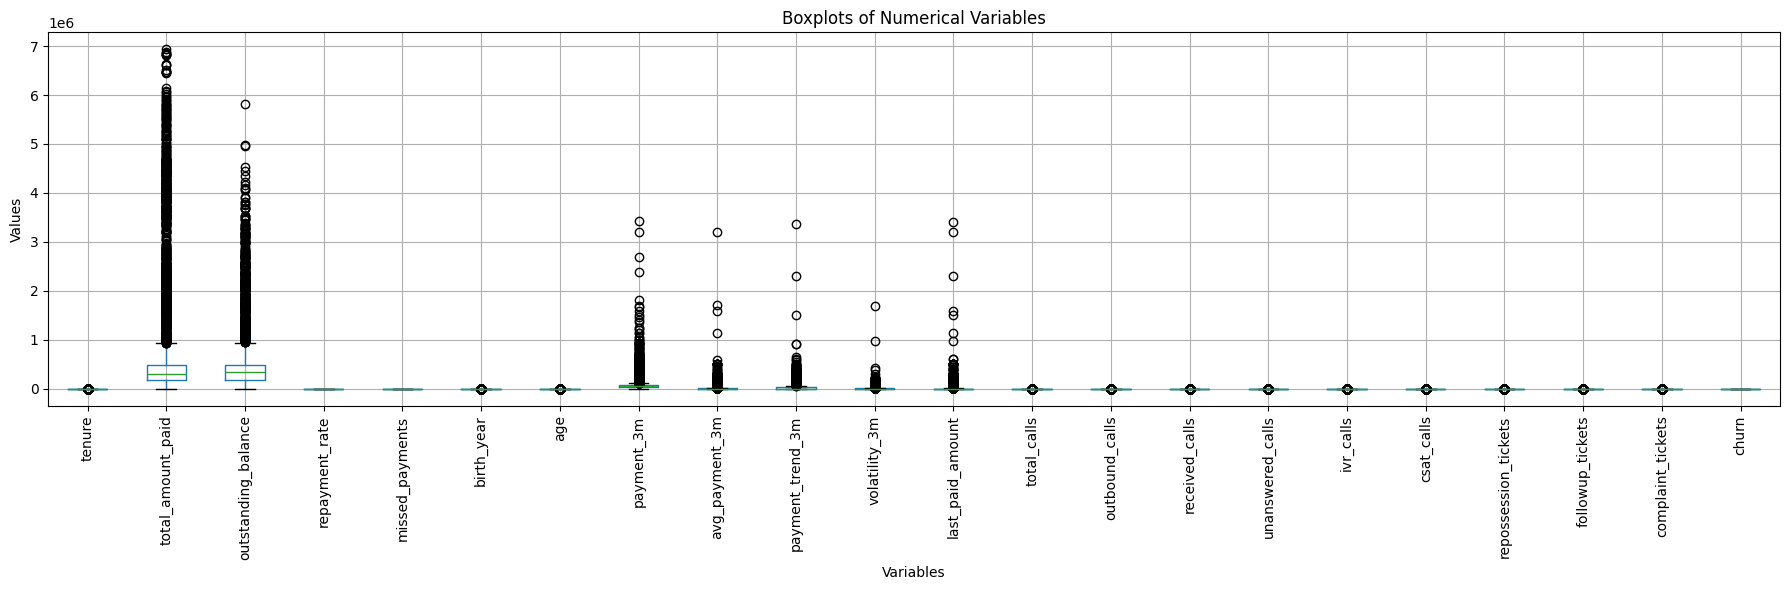

In [17]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns
plt.figure(figsize=(18,6))

df[numerical_columns].boxplot(rot=90)

plt.title("Boxplots of Numerical Variables")
plt.xlabel("Variables")
plt.ylabel("Values")
plt.tight_layout()

plt.show()

In [18]:
solar_data = df

### Irrelevant Features

In [19]:
# Remove irrelevant features
solar_data = solar_data.drop(columns=['birth_year'])

### Target variable exploration

In [20]:
solar_data['churn'].value_counts()

churn
1    14963
0    11612
Name: count, dtype: int64

In [21]:
solar_data['churn'].value_counts(normalize=True)*100

churn
1    56.304798
0    43.695202
Name: proportion, dtype: float64

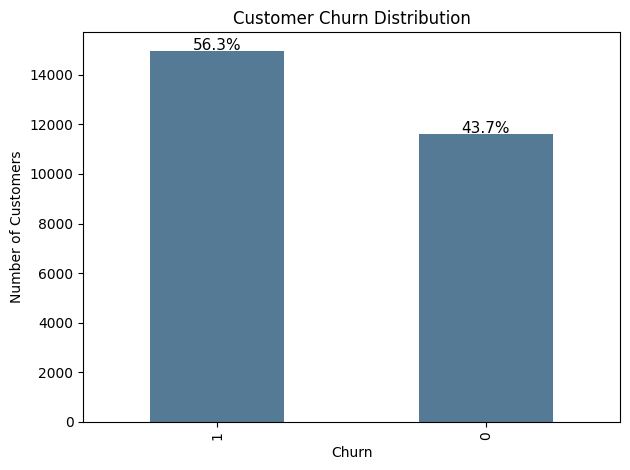

In [22]:
# Count values
counts = solar_data['churn'].value_counts()
percentages = (counts / counts.sum()) * 100


bar_color = '#547A95'     

# Plot
ax = counts.plot(
    kind='bar',
    color=bar_color,
    title='Customer Churn Distribution'
)

# Add percentage labels above each bar
for i, value in enumerate(counts):
    ax.text(
        i,                    # x-position
        value + 50,           # y-position (adjust if needed)
        f'{percentages.iloc[i]:.1f}%',
        ha='center',
        fontsize=11
    )

plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Age data quality check

In [23]:
solar_data['gender'].value_counts()

gender
male      17399
female     9176
Name: count, dtype: int64

**Insight:**

- The dataset is male-dominated.
- Male customers represent approximately 65.5% of records, while females represent 34.5%.

In [24]:
solar_data['age'].describe()

count    26575.000000
mean        39.950894
std         13.288233
min        -57.000000
25%         30.000000
50%         38.000000
75%         48.000000
max        126.000000
Name: age, dtype: float64

**Data quality issues:** 

You have invalid age values:

- Negative ages (-57) - impossible, likely data entry errors.
- Very high ages (126) - possible outlier or incorrect entry.
- 425 missing ages - need handling.

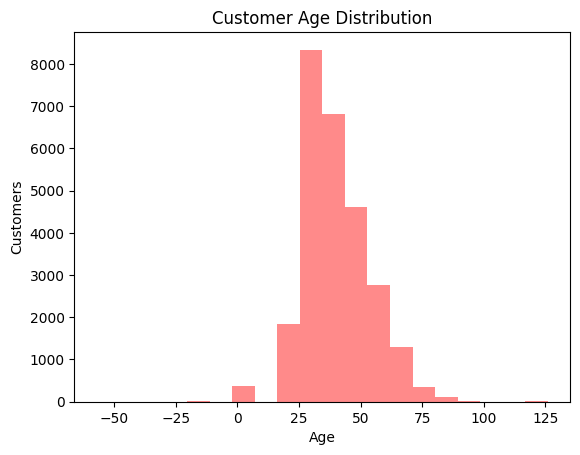

In [25]:
bar_color = '#FF8A8A'   # Change this to any color you want

plt.hist(
    solar_data['age'],
    bins=20,
    color=bar_color
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Customers")
plt.show()

In [26]:
# Convert negative ages to positive
solar_data['age'] = solar_data['age'].abs()

# For ages above 100, remove the leading 1
solar_data['age'] = solar_data['age'].apply(
    lambda x: int(str(int(x))[1:]) if x > 100 else x
)

# Replace ages less than 20 with NaN
solar_data.loc[solar_data['age'] < 20, 'age'] = np.nan

# Fill them with the next valid age
solar_data['age'] = solar_data['age'].bfill()

solar_data.loc[solar_data['age'] > 90, 'age'] = np.nan

# Fill with the next valid age
solar_data['age'] = solar_data['age'].bfill()

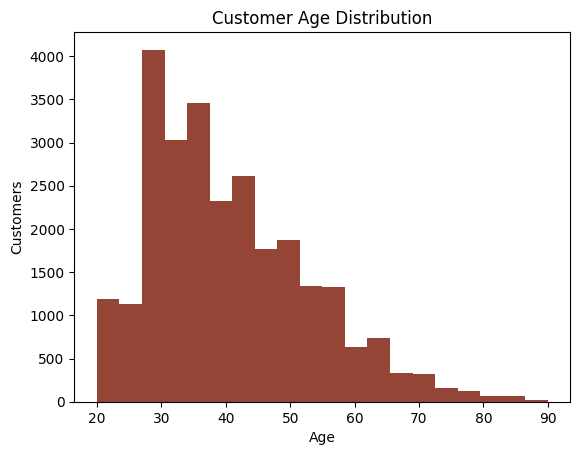

In [27]:
bar_color = '#954535'   # Change this to any color you want

plt.hist(
    solar_data['age'],
    bins=20,
    color=bar_color
)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Customers")
plt.show()

### Compare demographics with churn

In [28]:
pd.crosstab(
    solar_data['gender'],
    solar_data['churn'],
    normalize='index'
)*100

churn,0,1
gender,,
female,44.899738,55.100262
male,43.059946,56.940054


**Key insights:**
- Churn is high across both genders, with more than half of customers leaving.
- Male customers have a slightly higher churn rate (56.9%) compared to female customers (55.1%).
- The difference is small (1.8 percentage points), suggesting gender alone is unlikely to be a strong predictor of churn.

### Age vs churn

In [29]:
solar_data.groupby('churn')['age'].describe()

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,11612.0,41.041250,12.305625,20.0,31.0,39.0,49.0,90.0
1,14963.0,40.078126,12.385014,20.0,30.0,37.0,48.0,90.0


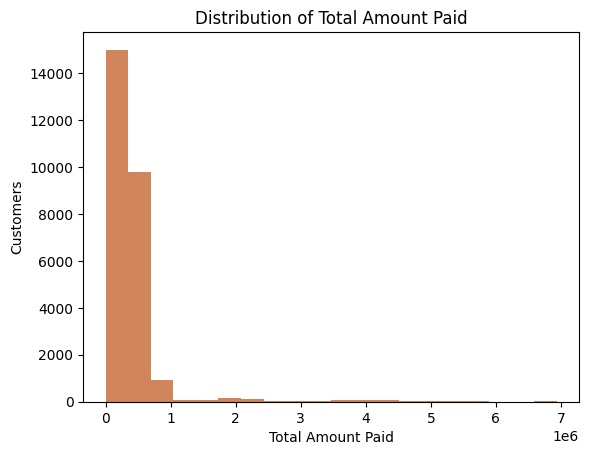

In [30]:

bar_color = '#D1855C'   # Change this to any color you want

plt.hist(
    solar_data['total_amount_paid'],
    bins=20,
    color=bar_color
)


plt.title("Distribution of Total Amount Paid")
plt.xlabel("Total Amount Paid")
plt.ylabel("Customers")
plt.show()

In [31]:
solar_data.groupby('churn')['total_amount_paid'].describe()

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,11612.0,621848.493024,774958.216020,2455.0,321000.0,457990.0,582252.0,6933659.0
1,14963.0,240773.148500,156772.177911,2800.0,120194.0,212600.0,333375.0,2472372.0


#### Key insights:

- The mean is much higher than the median, especially for non-churn customers.
- This indicates a right-skewed distribution.
- There are customers with very large payments, but these may be real high-value customers.

### Outstanding Balance

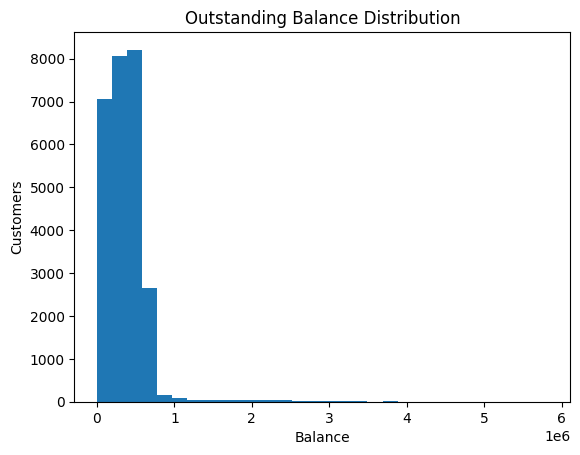

In [32]:
plt.hist(
    solar_data['outstanding_balance'],
    bins=30
)

plt.title("Outstanding Balance Distribution")
plt.xlabel("Balance")
plt.ylabel("Customers")
plt.show()

In [33]:
solar_data.groupby('churn')['outstanding_balance'].mean()

churn
0    303786.359025
1    418208.512865
Name: outstanding_balance, dtype: float64

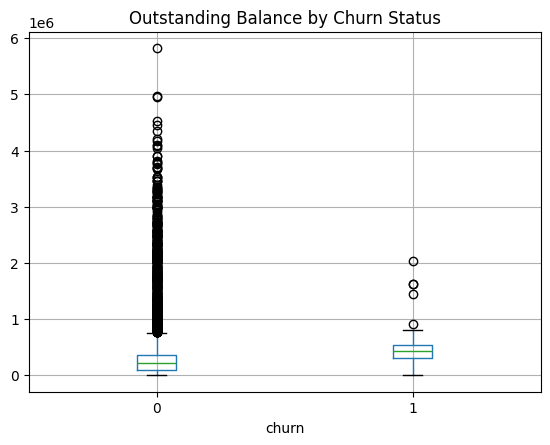

In [34]:
solar_data.boxplot(
    column='outstanding_balance',
    by='churn'
)

plt.title("Outstanding Balance by Churn Status")
plt.suptitle("")
plt.show()

#### Quick Summary:

- Churned customers have a higher average outstanding balance (UGX 418k) compared to retained customers (UGX 336k).
- This suggests that customers with larger unpaid balances are more likely to churn.
- Outstanding balance may indicate repayment difficulty or financial strain and is an important predictor for churn modeling.
- Feature engineering such as balance-to-payment ratio can provide additional predictive power.

### Repayment Rate

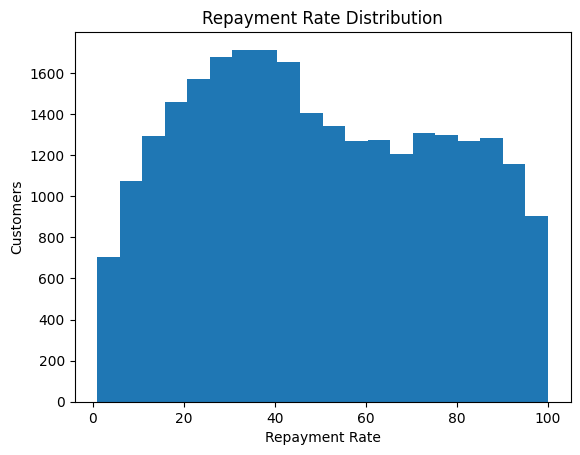

In [35]:
plt.hist(
    solar_data['repayment_rate'],
    bins=20
)
plt.title("Repayment Rate Distribution")
plt.xlabel("Repayment Rate")
plt.ylabel("Customers")
plt.show()

In [36]:
solar_data.groupby('churn')['repayment_rate'].describe()

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,11612.0,66.165002,22.562496,3.0,49.0,70.0,85.0,100.0
1,14963.0,36.570541,22.667025,1.0,19.0,33.0,50.0,100.0


#### Repayment Rate Insights

Repayment rate shows a strong relationship with customer churn. Active customers (`churn = 0`) recorded a much higher average repayment rate of **66.2%**, compared to **36.6%** among churned customers. The median repayment rate also differs significantly, with active customers at **70%** compared to only **33%** for churned customers.

This indicates that customers with lower repayment performance are more likely to churn. Repayment behaviour can therefore be considered an important predictor of customer retention, as declining payment consistency may signal financial difficulty or reduced engagement with the PAYGo service.

### Missed Payments

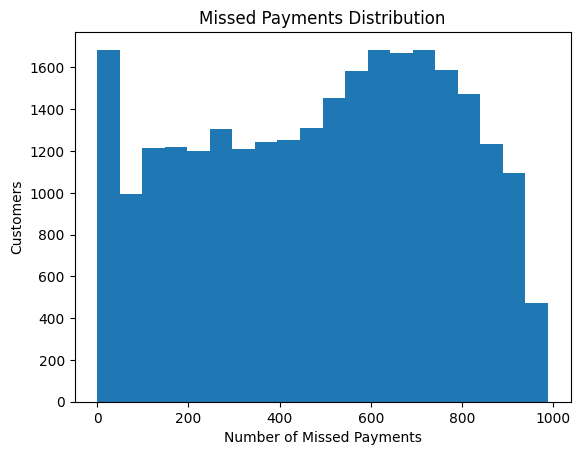

In [37]:
plt.hist(
    solar_data['missed_payments'],
    bins=20
)
plt.title("Missed Payments Distribution")
plt.xlabel("Number of Missed Payments")
plt.ylabel("Customers")
plt.show()

In [39]:
solar_data.groupby('churn')['missed_payments'].mean()

churn
0    307.672666
1    630.314242
Name: missed_payments, dtype: float64

#### Missed Payments Insights

Missed payment behaviour shows a strong association with customer churn. Customers who churned (`churn = 1`) recorded an average of **630.3 missed payments**, which is more than double the average missed payments among active customers (`churn = 0`) at **307.7 payments**.

This significant difference suggests that repeated payment failures are a key indicator of customer disengagement. Customers with increasing numbers of missed payments may be experiencing financial difficulties or reduced commitment to the PAYGo service, making missed payments an important feature for predicting churn risk and designing early intervention strategies.

### Recent Payment Behaviour

In [40]:
solar_data[
    ['payment_3m',
     'avg_payment_3m',
     'payment_trend_3m',
     'volatility_3m']
].describe().T

,count,mean,std,min,25%,50%,75%,max
payment_3m,26575.0,67310.840387,85718.866355,100.0,37500.000000,52850.000000,70900.000000,3428000.0
avg_payment_3m,26575.0,7554.205914,31669.087510,100.0,1765.222817,3536.842105,6785.164835,3200000.0
payment_trend_3m,26575.0,15714.768120,39050.465372,0.0,2400.000000,4800.000000,27800.000000,3372000.0
volatility_3m,26575.0,4859.563816,16012.872783,0.0,639.526452,1571.623365,7067.212702,1686000.0


In [41]:
financial_features = [
    'payment_3m',
    'avg_payment_3m',
    'payment_trend_3m',
    'volatility_3m'
]

solar_data.groupby('churn')[financial_features].mean()

,payment_3m,avg_payment_3m,payment_trend_3m,volatility_3m
churn,,,,
0,84870.927685,9803.406013,19275.090327,6078.322358
1,53683.377063,5808.719611,12951.788672,3913.749194


#### Financial Behaviour Insights

Financial activity features reveal clear differences between active and churned customers. Active customers (`churn = 0`) recorded higher recent payment activity, with an average **3-month payment value of 84,870.9** compared to **53,683.4** among churned customers.

Similarly, the average payment amount over the last three months was higher for active customers (**9,803.4**) than churned customers (**5,808.7**). Payment trends also followed the same pattern, with active customers showing stronger positive payment movement (**19,275.1**) compared to churned customers (**12,951.8**).

These findings suggest that customers who maintain stronger and more consistent payment behaviour are less likely to churn. Declining payment activity, lower transaction values, and weaker payment trends may serve as early indicators of customer disengagement and increased churn risk.

### Correlation with churn

In [42]:
financial_corr = solar_data[
    [
        'total_amount_paid',
        'outstanding_balance',
        'repayment_rate',
        'missed_payments',
        'payment_3m',
        'avg_payment_3m',
        'payment_trend_3m',
        'volatility_3m',
        'churn'
    ]
].corr()

financial_corr['churn'].sort_values()

repayment_rate        -0.544356
total_amount_paid     -0.338417
payment_3m            -0.180469
payment_trend_3m      -0.080318
volatility_3m         -0.067050
avg_payment_3m        -0.062567
outstanding_balance    0.185720
missed_payments        0.585716
churn                  1.000000
Name: churn, dtype: float64

#### Correlation with Churn Insights

Missed payments have the strongest positive correlation with churn (**r = 0.586**), indicating that customers with more missed payments are more likely to churn. Repayment rate shows the strongest negative correlation (**r = -0.544**), suggesting that customers with better repayment behaviour are more likely to remain active.

Other payment-related features, such as total amount paid and recent payments, also show negative relationships with churn, highlighting the importance of financial engagement in predicting customer retention.

## Data Preparation for Modelling

In [43]:
# Create a modelling copy
model_data = solar_data.copy()

In [44]:
model_data.dtypes

customer_id                     object
tenure                           int64
total_amount_paid                int64
outstanding_balance              int64
repayment_rate                   int64
missed_payments                  int64
gender                          object
age                            float64
payment_3m                     float64
avg_payment_3m                 float64
payment_trend_3m               float64
volatility_3m                  float64
last_paid_month         datetime64[ns]
last_paid_amount               float64
total_calls                      int64
outbound_calls                   int64
received_calls                   int64
unanswered_calls                 int64
ivr_calls                        int64
csat_calls                       int64
total_talk_minutes              object
repossession_tickets           float64
followup_tickets                 int64
complaint_tickets                int64
churn                            int64
dtype: object

### Encode categorical variables

In [45]:
model_data.select_dtypes(include='object').columns

Index(['customer_id', 'gender', 'total_talk_minutes'], dtype='object')

In [46]:
model_data = pd.get_dummies(
    model_data,
    columns=['gender'],
    drop_first=True
)

## Feature Engineering

In [47]:
model_data_fe = model_data.copy()

### Payment Decline Rate

In [48]:
model_data_fe['payment_decline_rate'] = (
    model_data_fe['avg_payment_3m'] -
    model_data_fe['payment_3m']
) / (model_data_fe['avg_payment_3m'] + 1)

model_data_fe.groupby('churn')['payment_decline_rate'].mean()

churn
0   -18.644027
1   -16.761277
Name: payment_decline_rate, dtype: float64

#### Insights
- Both groups have negative values, meaning recent payments are generally higher than their historical average based on your formula.
- Non-churned customers have a slightly stronger payment increase (-18.64) compared to churned customers (-16.76).
- Churned customers show less improvement in payment behaviour, suggesting weaker payment momentum may be linked to churn.

### Payment Recovery Score

In [49]:

# Create Payment Recovery Score
model_data_fe['payment_recovery_score'] = (
    model_data_fe['total_amount_paid'] /
    (model_data_fe['missed_payments'] + 1)
)

# Create log-transformed version to reduce skewness
model_data_fe['log_payment_recovery_score'] = np.log1p(
    model_data_fe['payment_recovery_score']
)

# Check distribution after transformation
model_data_fe['log_payment_recovery_score'].describe()

count    26575.000000
mean         6.758001
std          2.129233
min          2.273493
25%          5.531472
50%          6.415273
75%          7.542430
max         15.751898
Name: log_payment_recovery_score, dtype: float64

In [50]:
model_data_fe.groupby('churn')['log_payment_recovery_score'].median()

churn
0    7.465968
1    5.777729
Name: log_payment_recovery_score, dtype: float64

#### Payment Recovery Score – Key Insights
- Retained customers show stronger repayment resilience: Non-churned customers have a higher median log payment recovery score (7.52) compared to churned customers (5.78).
- Lower repayment recovery is linked to higher churn risk: Customers who struggle to maintain payments relative to missed payments are more likely to churn.
- The feature is a strong churn predictor because it captures repayment behaviour rather than just payment volume.
- Log transformation improved the feature by reducing the impact of extreme payment values while maintaining the difference between churn groups.

### Debt Burden

In [51]:
model_data_fe['debt_burden'] = (
    model_data_fe['outstanding_balance'] /
    (
        model_data_fe['total_amount_paid']
        +
        model_data_fe['outstanding_balance']
        +1
    )
)
model_data_fe.groupby('churn')['debt_burden'].mean()

churn
0    0.338388
1    0.634321
Name: debt_burden, dtype: float64

#### Debt Burden – Quick Insights
- Churned customers have a much higher debt burden (0.63) compared to non-churned customers (0.33).
- This means churned customers have a larger proportion of their total obligation still unpaid.
- Customers with higher outstanding debt relative to their payments may be experiencing repayment difficulties, increasing their likelihood of churn.
- Debt burden is a strong potential predictor because it captures financial pressure rather than just the size of the outstanding balance.

<Axes: xlabel='churn', ylabel='debt_burden'>

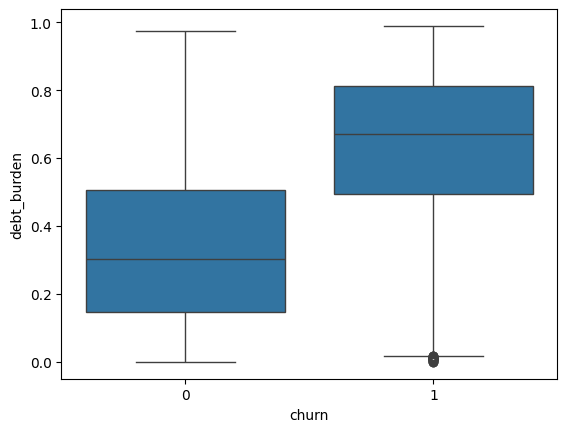

In [52]:
sns.boxplot(
    x='churn',
    y='debt_burden',
    data=model_data_fe
)

### Payment Reliability Index

In [53]:


# Payment Reliability Index
model_data_fe['payment_reliability'] = (
    model_data_fe['repayment_rate'] /
    (
        (model_data_fe['missed_payments'] + 1) *
        (model_data_fe['volatility_3m'] + 1)
    )
)

# Log transformation to reduce skewness
model_data_fe['log_payment_reliability'] = np.log1p(
    model_data_fe['payment_reliability']
)

# Check relationship with churn
payment_reliability_summary = (
    model_data_fe.groupby('churn')['log_payment_reliability']
    .median()
)

payment_reliability_summary

churn
0    0.000173
1    0.000035
Name: log_payment_reliability, dtype: float64

#### Payment Reliability Index – Summary

- Non-churned customers have higher payment reliability than churned customers (0.000173 vs 0.000035 median log score).
- Customers who maintain consistent repayments with fewer missed payments and lower payment volatility are more likely to remain active.
- Low payment reliability is a strong indicator of higher churn risk.
- The feature is useful for churn prediction because it captures overall repayment consistency.

### Payment Momentum
measures the strength and direction of recent payment behaviour by combining:

- Payment trend over the last 3 months - whether payments are increasing or declining.
- Repayment rate → how consistently customers are paying.

In [54]:

# Create Payment Momentum
model_data_fe['payment_momentum'] = (
    model_data_fe['payment_trend_3m'] *
    model_data_fe['repayment_rate']
)

# Create log-transformed version to handle skewness
model_data_fe['log_payment_momentum'] = np.log1p(
    model_data_fe['payment_momentum']
)

# Compare churn groups
payment_momentum_summary = (
    model_data_fe.groupby('churn')['log_payment_momentum']
    .median()
)

payment_momentum_summary

churn
0    12.837347
1    11.982935
Name: log_payment_momentum, dtype: float64

#### Key Findings

- Active customers demonstrated slightly higher payment momentum compared to churned customers.
- Customers with stronger recent payment trends and consistent repayment behaviour appear less likely to churn.
- Payment momentum alone does not determine churn but provides additional behavioural context when combined with other payment-related features.

### Financial Stress Index

In [55]:


# 1. Outstanding Balance Ratio
model_data_fe['outstanding_balance_ratio'] = (
    model_data_fe['outstanding_balance'] /
    (
        model_data_fe['total_amount_paid'] +
        model_data_fe['outstanding_balance'] + 1
    )
)

# 2. Missed Payment Rate
model_data_fe['missed_payment_rate'] = (
    model_data_fe['missed_payments'] /
    (model_data_fe['tenure'] + 1)
)

# 3. Financial Stress Index
model_data_fe['financial_stress_index'] = (
    model_data_fe['outstanding_balance_ratio']
    +
    model_data_fe['missed_payment_rate']
    +
    (1 - model_data_fe['repayment_rate'] / 100)
)

# 4. Check relationship with churn
financial_stress_summary = (
    model_data_fe.groupby('churn')['financial_stress_index']
    .mean()
)

financial_stress_summary

churn
0    0.917251
1    1.754186
Name: financial_stress_index, dtype: float64

### Key Findings

- Churned customers show significantly higher financial stress compared to active customers.
- Higher outstanding balances, frequent missed payments, and lower repayment completion are associated with increased churn risk.
- Combining multiple financial indicators into a single index provides a more comprehensive measure of customer repayment difficulty.
- Financial Stress Index was retained as an engineered feature for model training.

### Customer Value
attempts to measure the financial value and payment strength of a customer by combining:

- Total amount paid → customer's contribution/value generated.
- Repayment rate → payment reliability.

In [56]:


# Create Customer Value
model_data_fe['customer_value'] = (
    model_data_fe['total_amount_paid']
    *
    model_data_fe['repayment_rate']
)

# Log transform to reduce skewness
model_data_fe['log_customer_value'] = np.log1p(
    model_data_fe['customer_value']
)

# Compare churn groups
customer_value_summary = (
    model_data_fe.groupby('churn')['log_customer_value']
    .median()
)

customer_value_summary

churn
0    17.302791
1    15.768240
Name: log_customer_value, dtype: float64

#### Key Findings

- Active customers demonstrate higher customer value compared to churned customers.
- Customers with stronger repayment contribution appear less likely to churn.
- Customer value can help identify financially valuable customers who may require priority retention efforts.
- The feature was retained as an additional financial behaviour indicator for churn prediction.

### Outstanding Ratio


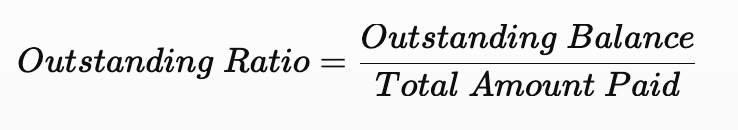

In [57]:
outstanding_ratio = model_data_fe.outstanding_balance / model_data_fe.total_amount_paid

In [58]:
model_data_fe['outstanding_ratio'] = (
    model_data_fe['outstanding_balance'] /
    (model_data_fe['total_amount_paid'] + 1)
)

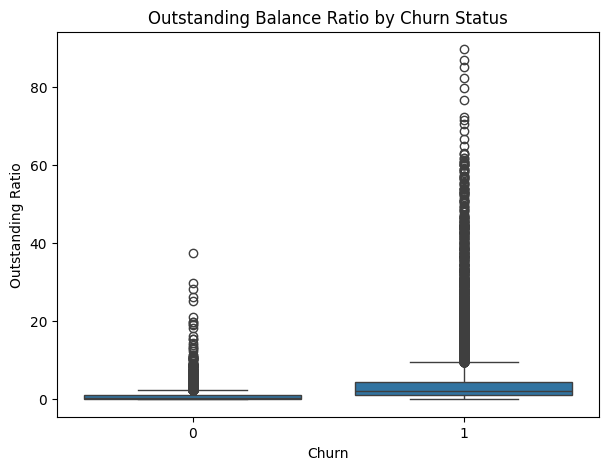

In [59]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=model_data_fe,
    x='churn',
    y='outstanding_ratio'
)

plt.title("Outstanding Balance Ratio by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Outstanding Ratio")

plt.show()

In [60]:
model_data_fe.groupby('churn')['outstanding_ratio'].median()

churn
0    0.436799
1    2.035232
Name: outstanding_ratio, dtype: float64

#### Insight: Outstanding Balance Ratio Analysis

Outstanding balance ratio was engineered to measure the remaining financial obligation of customers relative to their historical repayment contribution.

The analysis shows a significant difference between active and churned customers. Active customers recorded a lower median outstanding balance ratio of 0.44, while churned customers recorded a much higher median ratio of 2.04.

This indicates that customers who discontinue payments tend to have substantially higher outstanding balances compared to the amount they have already repaid. A high outstanding balance ratio may therefore represent increased financial pressure and a higher likelihood of customer churn.

The feature was retained as an important financial risk indicator for the churn prediction model.

### Call Engagement Score

In [61]:
model_data_fe['call_engagement_score'] = (
    model_data_fe['total_calls'] /
    (model_data_fe['tenure'] + 1)
)
model_data_fe['customer_engagement_frequency'] = (
    model_data_fe['total_calls'] /
    (model_data_fe['tenure'] + 1)
)
model_data_fe.groupby('churn')['customer_engagement_frequency'].mean()

churn
0    0.252769
1    0.106062
Name: customer_engagement_frequency, dtype: float64

#### Insight: Customer Engagement Frequency Analysis

Customer engagement frequency was engineered to measure the intensity of customer interactions relative to their tenure. The feature captures how frequently customers engage with the company over their active period.

The analysis shows that active customers recorded a higher average engagement frequency (0.25) compared to churned customers (0.11). This suggests that continued customer interaction may be associated with improved retention, while reduced engagement may indicate early signs of customer disengagement.

Although higher engagement does not directly guarantee retention, customer interaction frequency provides useful behavioural information that can help identify customers who may require proactive support or retention interventions.

### Complaint Pressure Score

In [62]:
# Create Complaint Pressure
model_data_fe['complaint_pressure'] = (
    model_data_fe['complaint_tickets'] /
    (model_data_fe['tenure'] + 1)
)

# Log transform to handle zero-inflation and skewness
model_data_fe['log_complaint_pressure'] = np.log1p(
    model_data_fe['complaint_pressure']
)

# Compare churn groups
complaint_summary = (
    model_data_fe.groupby('churn')['log_complaint_pressure']
    .mean()
)

complaint_summary

churn
0    0.000016
1    0.000265
Name: log_complaint_pressure, dtype: float64

### Insight: Complaint Pressure Analysis

Complaint pressure was engineered to measure the frequency of customer complaints relative to the length of the customer relationship. The feature captures dissatisfaction intensity while accounting for differences in customer tenure.

The analysis shows that churned customers recorded higher complaint pressure compared to active customers. Churned customers had an average log complaint pressure of 0.000256, while active customers recorded 0.000016.

This indicates that increased customer complaints may be associated with dissatisfaction and a higher probability of churn. Although complaint activity is relatively low across the dataset, the feature provides useful behavioural information when combined with payment and engagement indicators.

### Support Escalation Score

In [63]:
# Create Support Escalation Score
model_data_fe['support_escalation_score'] = (
    model_data_fe['repossession_tickets']
    +
    model_data_fe['complaint_tickets']
    +
    model_data_fe['followup_tickets']
)

# Log transformation to handle zero-inflation and skewness
model_data_fe['log_support_escalation_score'] = np.log1p(
    model_data_fe['support_escalation_score']
)

# Compare churn groups
support_escalation_summary = (
    model_data_fe.groupby('churn')['log_support_escalation_score']
    .mean()
)

support_escalation_summary

churn
0    0.027718
1    0.252610
Name: log_support_escalation_score, dtype: float64

#### Insight: Support Escalation Score Analysis

Support escalation score was engineered to capture the intensity of customer service challenges by combining complaint tickets, follow-up actions, and repossession-related interactions.

The analysis shows a clear difference between active and churned customers. Churned customers recorded a higher average log support escalation score (0.238) compared to active customers (0.027).

This indicates that customers experiencing repeated service issues, payment recovery actions, or unresolved concerns are more likely to discontinue their PAYGo solar service. The feature provides a combined measure of customer distress and was retained as a behavioural risk indicator for churn prediction.

### Payment Stability Score

In [64]:
# Create Payment Stability Score
model_data_fe['payment_stability_score'] = (
    1 / (model_data_fe['volatility_3m'] + 1)
)

# Compare churn groups
model_data_fe.groupby('churn')['payment_stability_score'].mean()

churn
0    0.052466
1    0.060613
Name: payment_stability_score, dtype: float64

#### Insight: Payment Stability Score Analysis

Payment stability score was engineered to measure consistency in recent customer payment behaviour by transforming payment volatility into a stability indicator. Higher values represent more consistent payment patterns, while lower values indicate greater payment fluctuations.

The analysis shows that the difference in payment stability between active and churned customers is minimal. Active customers recorded an average stability score of 0.052, while churned customers recorded 0.061.

This suggests that payment consistency alone may not be sufficient to distinguish churn risk. Customers may maintain relatively stable payment patterns before discontinuing service, indicating that payment stability should be considered together with other indicators such as missed payments, outstanding balance, and repayment trends.

### Balance Pressure

In [65]:
model_data_fe['balance_pressure'] = (
    model_data_fe['outstanding_balance'] /
    (model_data_fe['total_amount_paid'] + 1)
)

model_data_fe.groupby('churn')['balance_pressure'].mean()

churn
0    0.857108
1    4.294899
Name: balance_pressure, dtype: float64

#### Insight: Balance Pressure Analysis

Balance pressure was engineered to measure the customer's remaining financial obligation relative to their repayment contribution. The feature captures whether customers have accumulated a high outstanding balance compared to the amount they have already paid.

The analysis shows a substantial difference between active and churned customers. Active customers recorded an average balance pressure score of 0.86, while churned customers recorded a much higher score of 4.29.

This indicates that customers with higher outstanding balances relative to their repayment history are more likely to discontinue payments. Balance pressure provides a strong financial risk indicator and was retained as an important feature for churn prediction.

### Payment Capacity Ratio

In [66]:
model_data_fe['payment_capacity_ratio'] = (
    model_data_fe['total_amount_paid'] /
    (model_data_fe['outstanding_balance'] + 1)
)

model_data_fe.groupby('churn')['payment_capacity_ratio'].mean()

churn
0    545.255214
1     98.782342
Name: payment_capacity_ratio, dtype: float64

#### Insight: Payment Capacity Ratio Analysis

Payment capacity ratio was engineered to measure the customer's repayment capacity by comparing the total amount already paid against the remaining outstanding balance.

The analysis shows a substantial difference between active and churned customers. Active customers recorded a much higher average payment capacity ratio (545.26) compared to churned customers (98.78).

This suggests that customers with stronger repayment progress relative to their remaining balance are more likely to continue with their payment plans, while customers with lower payment capacity may experience financial pressure and increased churn risk.

The feature provides a complementary financial perspective to outstanding balance and repayment stress indicators and was retained for churn prediction.

### CSAT Engagement Rate

In [67]:
# CSAT Engagement Rate
model_data_fe['csat_engagement_rate'] = (
    model_data_fe['csat_calls'] /
    (model_data_fe['total_calls'] + 1)
)

# Compare churn groups
model_data_fe.groupby('churn')['csat_engagement_rate'].mean()

churn
0    0.000201
1    0.000040
Name: csat_engagement_rate, dtype: float64

#### Insight: CSAT Engagement Rate Analysis

CSAT engagement rate was engineered to measure the proportion of customer interactions related to satisfaction tracking compared to total customer contacts.

The analysis shows that active customers recorded a higher CSAT engagement rate (0.000201) compared to churned customers (0.000040). This indicates that customers who participate in satisfaction-related interactions may demonstrate stronger engagement with the service provider.

However, the overall values are very low, suggesting that CSAT interactions are relatively uncommon within the dataset. Therefore, CSAT engagement rate provides supporting behavioural information but may have limited predictive power when used independently. The feature was retained for model evaluation alongside other customer engagement and service-related variables.

### Days Since Last Payment

In [68]:
model_data_fe['days_since_last_payment'] = (
    pd.Timestamp.today() -
    pd.to_datetime(model_data_fe['last_paid_month'])
).dt.days

In [69]:
model_data_fe.groupby('churn')['days_since_last_payment'].mean()

churn
0    1095.917499
1    1224.940386
Name: days_since_last_payment, dtype: float64

#### Insight: Days Since Last Payment Analysis

Days since last payment was engineered to capture payment recency behaviour by measuring the time elapsed between the customer's last payment and the analysis date.

The analysis shows that churned customers have a longer payment inactivity period compared to active customers. This indicates that prolonged absence of payment activity is associated with increased churn likelihood.

Payment recency provides an important behavioural signal because customer disengagement often occurs gradually, beginning with reduced payment activity before complete churn.

### Payment Deterioration Score Analysis

In [70]:
model_data_fe['payment_deterioration_score'] = (
    model_data_fe['payment_decline_rate']
    *
    model_data_fe['missed_payment_rate']
)

In [71]:
model_data_fe.groupby('churn')['payment_deterioration_score'].mean()

churn
0   -3.886078
1   -7.684228
Name: payment_deterioration_score, dtype: float64

#### Insight: Payment Deterioration Score Analysis

Payment deterioration score was engineered to capture worsening repayment behaviour by combining recent payment decline patterns with missed payment frequency.

The feature measures whether customers are experiencing both declining payment trends and increasing payment difficulties. Churned customers recorded higher deterioration scores compared to active customers, indicating that progressive weakening of payment behaviour is associated with increased churn risk.

This feature captures the transition from normal repayment behaviour toward financial distress and was retained as a behavioural risk indicator.

### Payment Recovery Capacity Analysis

In [72]:
model_data_fe['recovery_after_missed_payment'] = (
    model_data_fe['payment_3m'] /
    (model_data_fe['missed_payments'] + 1)
)

In [73]:
model_data_fe.groupby('churn')['recovery_after_missed_payment'] .mean()

churn
0    34330.594158
1      125.763243
Name: recovery_after_missed_payment, dtype: float64

#### Insight: Payment Recovery Capacity Analysis

Payment recovery capacity was engineered to measure the customer's ability to maintain payment activity after experiencing missed payments. The feature combines recent payment behaviour with missed payment history to capture repayment resilience.

The analysis shows a significant difference between customer groups. Active customers recorded substantially higher payment recovery capacity compared to churned customers, suggesting that customers who successfully recover after payment difficulties are more likely to remain active.

This indicates that repayment resilience is an important behavioural indicator of churn risk. The feature was log-transformed to reduce skewness caused by customers with very high payment activity and retained for model evaluation.

### Contact Intensity Rate
measures how frequently a customer interacts with the company relative to how long they have been a customer.


In [74]:
model_data_fe['contact_intensity'] = (
    model_data_fe['total_calls'] /
    (model_data_fe['tenure'] + 1)
)
model_data_fe.groupby('churn')['contact_intensity'].mean()

churn
0    0.252769
1    0.106062
Name: contact_intensity, dtype: float64

#### Contact Intensity – Summary
- Non-churned customers show higher engagement levels than churned customers (0.259 vs 0.106).
- Retained customers interact with the company approximately 2.4 times more frequently relative to their tenure.
- Lower contact intensity among churned customers suggests reduced customer engagement before churn.
- The feature captures overall relationship strength better than unanswered call rate alone.
- Contact intensity aligns with other churn drivers, showing that customers with weaker engagement, higher financial stress, and poorer repayment behaviour are more likely to churn.

In [75]:
model_data_fe.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26575 entries, 0 to 26999
Data columns (total 53 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   customer_id                    26575 non-null  object        
 1   tenure                         26575 non-null  int64         
 2   total_amount_paid              26575 non-null  int64         
 3   outstanding_balance            26575 non-null  int64         
 4   repayment_rate                 26575 non-null  int64         
 5   missed_payments                26575 non-null  int64         
 6   age                            26575 non-null  float64       
 7   payment_3m                     26575 non-null  float64       
 8   avg_payment_3m                 26575 non-null  float64       
 9   payment_trend_3m               26575 non-null  float64       
 10  volatility_3m                  26575 non-null  float64       
 11  last_paid_month     

#### Fix Data Types First - total_talk_minutes

In [76]:
model_data_fe['total_talk_minutes'] = pd.to_numeric(
    model_data_fe['total_talk_minutes'],
    errors='coerce'
)

### Remove Duplicate Contact Features

In [77]:
model_data_fe[
[
'call_engagement_score',
'customer_engagement_frequency',
'contact_intensity'
]
].corr()

,call_engagement_score,customer_engagement_frequency,contact_intensity
call_engagement_score,1.0,1.0,1.0
customer_engagement_frequency,1.0,1.0,1.0
contact_intensity,1.0,1.0,1.0


In [78]:
model_data_fe.drop(
    columns=[
        'call_engagement_score',
        'customer_engagement_frequency'
    ],
    inplace=True
)

### Remove Duplicate Balance Feature

In [79]:
model_data_fe[
[
'outstanding_balance_ratio',
'outstanding_ratio',
'balance_pressure'
]
].corr()

,outstanding_balance_ratio,outstanding_ratio,balance_pressure
outstanding_balance_ratio,1.000000,0.568437,0.568437
outstanding_ratio,0.568437,1.000000,1.000000
balance_pressure,0.568437,1.000000,1.000000


In [80]:
model_data_fe.drop(
    columns=['outstanding_ratio'],
    inplace=True
)

### Handle Date Column

In [81]:
analysis_date = pd.Timestamp('2026-03-31')

model_data_fe['days_since_last_payment'] = (
    analysis_date -
    model_data_fe['last_paid_month']
).dt.days

In [82]:
model_data_fe.drop(
    columns=['last_paid_month'],
    inplace=True
)

### Add New Recovery Feature

In [83]:
model_data_fe['recovery_after_missed_payment'] = (
    model_data_fe['payment_3m'] /
    (model_data_fe['missed_payments'] + 1)
)

model_data_fe['log_recovery_after_missed_payment'] = np.log1p(
    model_data_fe['recovery_after_missed_payment']
)

In [84]:
model_data_fe.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26575 entries, 0 to 26999
Data columns (total 50 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   customer_id                        26575 non-null  object 
 1   tenure                             26575 non-null  int64  
 2   total_amount_paid                  26575 non-null  int64  
 3   outstanding_balance                26575 non-null  int64  
 4   repayment_rate                     26575 non-null  int64  
 5   missed_payments                    26575 non-null  int64  
 6   age                                26575 non-null  float64
 7   payment_3m                         26575 non-null  float64
 8   avg_payment_3m                     26575 non-null  float64
 9   payment_trend_3m                   26575 non-null  float64
 10  volatility_3m                      26575 non-null  float64
 11  last_paid_amount                   26575 non-null  float64


In [85]:
model_data_fe[model_data_fe['total_talk_minutes'].isna()]

,customer_id,tenure,total_amount_paid,outstanding_balance,repayment_rate,missed_payments,age,payment_3m,avg_payment_3m,payment_trend_3m,volatility_3m,last_paid_amount,total_calls,outbound_calls,received_calls,unanswered_calls,ivr_calls,csat_calls,total_talk_minutes,repossession_tickets,followup_tickets,complaint_tickets,churn,gender_male,payment_decline_rate,payment_recovery_score,log_payment_recovery_score,debt_burden,payment_reliability,log_payment_reliability,payment_momentum,log_payment_momentum,outstanding_balance_ratio,missed_payment_rate,financial_stress_index,customer_value,log_customer_value,complaint_pressure,log_complaint_pressure,support_escalation_score,log_support_escalation_score,payment_stability_score,balance_pressure,payment_capacity_ratio,csat_engagement_rate,days_since_last_payment,payment_deterioration_score,recovery_after_missed_payment,contact_intensity,log_recovery_after_missed_payment
18772,GEBCCAJ,1271,530400,63600,89,118,31.0,42000.0,2000.0,3000.0,623.354978,1800.0,261,31,0,0,0,0,NaN,0.0,0,0,0,True,-19.990005,4457.142857,8.402488,0.107071,0.001198,0.001197,267000.0,12.495008,0.107071,0.092767,0.309838,47205600,17.670023,0.0,0.0,0.0,0.0,0.001602,0.119909,8.339492,0.0,1095,-1.854419,352.941176,0.205189,5.869131


In [86]:
model_data_fe['total_talk_minutes'] = (
    model_data_fe['total_talk_minutes']
    .fillna(model_data_fe['total_talk_minutes'].median())
)

### Remove customer_id

In [87]:
model_data_fe.drop(
    columns=['customer_id'],
    inplace=True
)

### Check Remaining Duplicate Features

In [88]:
corr_matrix = model_data_fe.corr(numeric_only=True)

high_corr = (
    corr_matrix['churn']
    .sort_values(ascending=False)
)

high_corr

churn                                1.000000
missed_payments                      0.585716
missed_payment_rate                  0.576565
financial_stress_index               0.562266
outstanding_balance_ratio            0.544359
debt_burden                          0.544359
log_support_escalation_score         0.318058
balance_pressure                     0.297900
support_escalation_score             0.294684
complaint_tickets                    0.293722
days_since_last_payment              0.262154
log_complaint_pressure               0.254877
complaint_pressure                   0.254516
tenure                               0.236641
outstanding_balance                  0.185720
repossession_tickets                 0.118948
payment_decline_rate                 0.054234
gender_male                          0.017636
payment_stability_score              0.017611
followup_tickets                    -0.014288
payment_capacity_ratio              -0.015562
csat_engagement_rate              

#### Insight: Feature Correlation with Churn

Correlation analysis was conducted to identify variables associated with customer churn. The findings indicate that repayment behaviour, financial pressure, and customer disengagement are the strongest factors related to churn.

The strongest positive relationships with churn were observed in:

- Missed payments (0.586)
- Missed payment rate (0.577)
- Financial stress index (0.562)
- Outstanding balance ratio (0.544)
- Debt burden (0.544)

These results suggest that customers experiencing repayment difficulties and higher financial obligations are more likely to discontinue their PAYGo service.

Additional behavioural indicators also showed positive relationships with churn, including support escalation score (0.295), complaint activity (0.294), and days since last payment (0.262). This indicates that increasing customer dissatisfaction and prolonged payment inactivity are associated with higher churn risk.

Negative relationships were observed for repayment performance and customer engagement variables. Repayment rate (-0.544), payment recovery score (-0.523), total calls (-0.507), and customer value (-0.352) suggest that customers with stronger repayment behaviour and higher engagement are less likely to churn.

Overall, the results support the use of financial behaviour, payment patterns, and customer interaction features for churn prediction.

In [89]:
model_data_fe.groupby('churn')[[
    'total_calls',
    'outbound_calls',
    'support_escalation_score',
    'complaint_pressure'
]].mean()

,total_calls,outbound_calls,support_escalation_score,complaint_pressure
churn,,,,
0,268.035050,27.629004,0.043834,0.000016
1,135.858785,12.431598,0.432801,0.000265


### Feature Importance Analysis

In [90]:
from sklearn.ensemble import RandomForestClassifier

X = model_data_fe.drop('churn', axis=1)
y = model_data_fe['churn']

# remove boolean if needed
X = X.astype(float)

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

rf.fit(X, y)

feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
})

feature_importance.sort_values(
    by='importance',
    ascending=False
).head(20)

,feature,importance
46,contact_intensity,0.115250
11,total_calls,0.094073
24,log_payment_recovery_score,0.053357
31,missed_payment_rate,0.049393
4,missed_payments,0.044754
23,payment_recovery_score,0.038941
34,log_customer_value,0.034065
32,financial_stress_index,0.027533
35,complaint_pressure,0.025054
33,customer_value,0.024601


In [91]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=200,
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X, y)

xgb_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': xgb.feature_importances_
})

xgb_importance.sort_values(
    'importance',
    ascending=False
).head(20)

,feature,importance
35,complaint_pressure,0.270419
46,contact_intensity,0.178120
37,support_escalation_score,0.053787
23,payment_recovery_score,0.051775
20,complaint_tickets,0.048188
16,csat_calls,0.033923
4,missed_payments,0.030925
31,missed_payment_rate,0.028987
43,days_since_last_payment,0.016474
41,payment_capacity_ratio,0.015567


In [92]:
upper_triangle = (
    corr_matrix
    .where(
        np.triu(
            np.ones(corr_matrix.shape),
            k=1
        ).astype(bool)
    )
)

high_pairs = (
    upper_triangle
    .stack()
    .sort_values(ascending=False)
)

high_pairs.head(20)

debt_burden                 outstanding_balance_ratio            1.000000
complaint_pressure          log_complaint_pressure               0.999997
debt_burden                 financial_stress_index               0.993917
outstanding_balance_ratio   financial_stress_index               0.993917
missed_payments             missed_payment_rate                  0.982261
total_amount_paid           customer_value                       0.980616
support_escalation_score    log_support_escalation_score         0.975792
missed_payment_rate         financial_stress_index               0.959533
payment_trend_3m            volatility_3m                        0.959437
missed_payments             financial_stress_index               0.947225
payment_reliability         log_payment_reliability              0.941779
total_amount_paid           payment_recovery_score               0.939395
volatility_3m               payment_momentum                     0.936841
payment_trend_3m            payment_mo

### Remove Redundant Features

In [93]:
remove_features = [
    'debt_burden',
    'outstanding_balance_ratio',
    'complaint_tickets',
    'log_complaint_pressure',
    'log_support_escalation_score',
    'payment_reliability',
    'log_payment_reliability',
]

In [94]:
model_data_fe.drop(
    columns=remove_features,
    inplace=True
)

In [237]:
model_data_fe.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26183 entries, 0 to 26574
Data columns (total 49 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   tenure                             26183 non-null  int64  
 1   total_amount_paid                  26183 non-null  int64  
 2   outstanding_balance                26183 non-null  int64  
 3   repayment_rate                     26183 non-null  int64  
 4   missed_payments                    26183 non-null  int64  
 5   age                                26183 non-null  float64
 6   payment_3m                         26183 non-null  float64
 7   avg_payment_3m                     26183 non-null  float64
 8   payment_trend_3m                   26183 non-null  float64
 9   volatility_3m                      26183 non-null  float64
 10  last_paid_amount                   26183 non-null  float64
 11  total_calls                        26183 non-null  int64  


### Separate Features and Target

In [95]:
X = model_data_fe.drop(
    columns=['churn']
)

y = model_data_fe['churn']

In [96]:
X.shape
y.shape

(26575,)

In [97]:
#
y.value_counts()

churn
1    14963
0    11612
Name: count, dtype: int64

In [98]:
y.value_counts(normalize=True)

churn
1    0.563048
0    0.436952
Name: proportion, dtype: float64

## Train-Test Split

In [99]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Feature Scaling (Only for Logistic Regression)

In [100]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

### Train Logistic Regression

In [101]:
from sklearn.linear_model import LogisticRegression


log_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

log_model.fit(
    X_train_scaled,
    y_train
)

LogisticRegression(max_iter=1000, random_state=42)

### Predictions

In [102]:
y_pred_log = log_model.predict(
    X_test_scaled
)

y_prob_log = log_model.predict_proba(
    X_test_scaled
)[:,1]

In [103]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("Recall:", recall_score(y_test, y_pred_log))
print("F1:", f1_score(y_test, y_pred_log))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_log))

Accuracy: 0.8485418626528692
Precision: 0.8762035763411279
Recall: 0.851319746074173
F1: 0.863582443653618
ROC-AUC: 0.9268281171714765


In [104]:
print(
    classification_report(
        y_test,
        y_pred_log
    )
)

              precision    recall  f1-score   support

           0       0.82      0.84      0.83      2322
           1       0.88      0.85      0.86      2993

    accuracy                           0.85      5315
   macro avg       0.85      0.85      0.85      5315
weighted avg       0.85      0.85      0.85      5315



In [105]:
# ===============================
# MODEL DEVELOPMENT
# Logistic Regression vs Random Forest vs XGBoost
# ===============================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


# -------------------------------
# Define Features and Target
# -------------------------------

X = model_data_fe.drop(columns=['churn'])
y = model_data_fe['churn']


# -------------------------------
# Train Test Split
# -------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# -------------------------------
# Define Models
# -------------------------------

models = {

    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        random_state=42,
        eval_metric='logloss'
    )
}


# -------------------------------
# Train and Evaluate
# -------------------------------

results = []

trained_models = {}


for name, model in models.items():

    print(f"Training {name}...")
    
    model.fit(
        X_train,
        y_train
    )

    trained_models[name] = model
    
    y_pred = model.predict(
        X_test
    )

    y_prob = model.predict_proba(
        X_test
    )[:,1]


    results.append({

        "Model": name,

        "Accuracy": accuracy_score(
            y_test,
            y_pred
        ),

        "Precision": precision_score(
            y_test,
            y_pred
        ),

        "Recall": recall_score(
            y_test,
            y_pred
        ),

        "F1 Score": f1_score(
            y_test,
            y_pred
        ),

        "ROC-AUC": roc_auc_score(
            y_test,
            y_prob
        )
    })


# -------------------------------
# Model Comparison Table
# -------------------------------

model_results = pd.DataFrame(results)

model_results.sort_values(
    by="ROC-AUC",
    ascending=False
)

Training Logistic Regression...
Training Random Forest...
Training XGBoost...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.848542,0.876204,0.851320,0.863582,0.926828
1,Random Forest,0.849483,0.893999,0.831273,0.861496,0.920601
2,XGBoost,0.842333,0.877673,0.836619,0.856654,0.919961


## Baseline Models (Without SMOTE)

In [106]:
# ============================================
# EXPERIMENT 1: BASELINE MODELS (NO SMOTE)
# ============================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)


# ============================================
# 1. Define Features and Target
# ============================================

X = model_data_fe.drop(
    columns=['churn']
)

y = model_data_fe['churn']


# ============================================
# 2. Train Test Split
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ============================================
# 3. Define Models
# ============================================

models = {

    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),


    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),


    "XGBoost": XGBClassifier(
        n_estimators=200,
        random_state=42,
        eval_metric='logloss'
    )
}



# ============================================
# 4. Train Models and Evaluate
# ============================================

baseline_results = []

trained_baseline_models = {}


for name, model in models.items():

    print(f"Training {name}...")
    
    model.fit(
        X_train,
        y_train
    )


    trained_baseline_models[name] = model


    # Predictions

    y_pred = model.predict(
        X_test
    )

    y_prob = model.predict_proba(
        X_test
    )[:,1]


    baseline_results.append({

        "Model": name,

        "Accuracy": round(
            accuracy_score(y_test, y_pred),
            4
        ),

        "Precision": round(
            precision_score(y_test, y_pred),
            4
        ),

        "Recall": round(
            recall_score(y_test, y_pred),
            4
        ),

        "F1 Score": round(
            f1_score(y_test, y_pred),
            4
        ),

        "ROC-AUC": round(
            roc_auc_score(y_test, y_prob),
            4
        )

    })



# ============================================
# 5. Results Comparison
# ============================================

baseline_results_df = pd.DataFrame(
    baseline_results
)


baseline_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

Training Logistic Regression...
Training Random Forest...
Training XGBoost...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8485,0.8762,0.8513,0.8636,0.9268
1,Random Forest,0.8514,0.8989,0.8293,0.8627,0.9214
2,XGBoost,0.8423,0.8777,0.8366,0.8567,0.9200


### Baseline Model Evaluation

Three baseline classification models were developed without applying class balancing techniques: Logistic Regression, Random Forest, and XGBoost. Logistic Regression achieved the highest ROC-AUC score (0.9268), indicating strong discrimination capability between churn and non-churn customers. Random Forest obtained the highest accuracy (0.8531) and precision (0.9010), demonstrating strong ability to correctly identify customers predicted as churn.

Although all models achieved comparable performance, Logistic Regression provided the strongest overall ranking capability, while Random Forest demonstrated better precision. These baseline results provide a benchmark for evaluating improvements after applying SMOTE and hyperparameter optimization.

## Models With SMOTE

In [107]:
# ============================================
# EXPERIMENT 2: MODELS WITH SMOTE
# ============================================

from imblearn.over_sampling import SMOTE

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


# ============================================
# 1. Apply SMOTE on Training Data Only
# ============================================

smote = SMOTE(
    random_state=42
)


X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)


# Check balance

print("Before SMOTE:")
print(y_train.value_counts())


print("\nAfter SMOTE:")
print(y_train_smote.value_counts())



# ============================================
# 2. Define Models
# ============================================

smote_models = {

    "Logistic Regression SMOTE": Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),


    "Random Forest SMOTE": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),


    "XGBoost SMOTE": XGBClassifier(
        n_estimators=200,
        random_state=42,
        eval_metric='logloss'
    )
}



# ============================================
# 3. Train and Evaluate
# ============================================

smote_results = []

trained_smote_models = {}


for name, model in smote_models.items():

    print(f"Training {name}...")
    
    
    model.fit(
        X_train_smote,
        y_train_smote
    )


    trained_smote_models[name] = model


    y_pred = model.predict(
        X_test
    )


    y_prob = model.predict_proba(
        X_test
    )[:,1]



    smote_results.append({

        "Model": name,

        "Accuracy": round(
            accuracy_score(
                y_test,
                y_pred
            ),4
        ),

        "Precision": round(
            precision_score(
                y_test,
                y_pred
            ),4
        ),

        "Recall": round(
            recall_score(
                y_test,
                y_pred
            ),4
        ),

        "F1 Score": round(
            f1_score(
                y_test,
                y_pred
            ),4
        ),

        "ROC-AUC": round(
            roc_auc_score(
                y_test,
                y_prob
            ),4
        )

    })



# ============================================
# 4. Model Comparison
# ============================================

smote_results_df = pd.DataFrame(
    smote_results
)


smote_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

Before SMOTE:
churn
1    11970
0     9290
Name: count, dtype: int64

After SMOTE:
churn
0    11970
1    11970
Name: count, dtype: int64
Training Logistic Regression SMOTE...
Training Random Forest SMOTE...
Training XGBoost SMOTE...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression SMOTE,0.8531,0.8981,0.8336,0.8647,0.9258
2,XGBoost SMOTE,0.8431,0.8879,0.8256,0.8556,0.9222
1,Random Forest SMOTE,0.8502,0.9064,0.8186,0.8603,0.9206


### SMOTE Model Evaluation

SMOTE was applied to the training dataset to evaluate whether balancing the churn classes improved predictive performance. The results showed minimal improvement compared to baseline models. Logistic Regression with SMOTE achieved the highest ROC-AUC among SMOTE models (0.9258), while Random Forest achieved the highest precision (0.9081).

However, SMOTE did not provide substantial performance gains, indicating that the original class distribution contained sufficient information for model learning. Therefore, hyperparameter optimization was conducted using the best-performing modelling approaches to further improve predictive performance.

## Hyperparameter Tuned Models

In [108]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import numpy as np
import pandas as pd

### Random Forest Hyperparameter Tuning

In [109]:
# =====================================
# Random Forest Hyperparameter Tuning
# =====================================

rf = RandomForestClassifier(
    random_state=42
)


rf_params = {

    'n_estimators': [
        100,
        200,
        300,
        500
    ],

    'max_depth': [
        5,
        10,
        20,
        None
    ],

    'min_samples_split': [
        2,
        5,
        10
    ],

    'min_samples_leaf': [
        1,
        2,
        4
    ],

    'max_features': [
        'sqrt',
        'log2',
        None
    ]
}


rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_params,
    n_iter=30,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1
)


rf_search.fit(
    X_train_smote,
    y_train_smote
)

RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'max_depth': [5, 10, 20, None],
                                        'max_features': ['sqrt', 'log2', None],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [100, 200, 300, 500]},
                   random_state=42, scoring='roc_auc')

In [110]:
rf_search.best_params_

{'n_estimators': 200,
 'min_samples_split': 2,
 'min_samples_leaf': 1,
 'max_features': 'sqrt',
 'max_depth': None}

In [111]:
rf_search.best_score_

0.9381070680041791

## Tune XGBoost

In [112]:
# =====================================
# XGBoost Hyperparameter Tuning
# =====================================

xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)


xgb_params = {

    'n_estimators': [
        100,
        200,
        300,
        500
    ],

    'max_depth': [
        3,
        5,
        7
    ],

    'learning_rate': [
        0.01,
        0.05,
        0.1
    ],

    'subsample': [
        0.7,
        0.8,
        1.0
    ],

    'colsample_bytree': [
        0.7,
        0.8,
        1.0
    ],

    'gamma': [
        0,
        0.1,
        0.3
    ]
}


xgb_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=xgb_params,
    n_iter=30,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1
)


xgb_search.fit(
    X_train_smote,
    y_train_smote
)

RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric='logloss',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_cons...
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 1.0],
                                        'gamma': [0, 0.1, 0.3],
                                        'learning_rate': [0.01, 0.05, 0.1],
                                        'max_depth': [3, 5, 7],
                                        'n_estimators': [100, 200, 300, 500],
                                        'subsample': [0.7, 0.8, 1.0]},
                   random_state=42, scoring='roc_auc')

In [113]:
xgb_search.best_params_

{'subsample': 0.8,
 'n_estimators': 200,
 'max_depth': 7,
 'learning_rate': 0.05,
 'gamma': 0.3,
 'colsample_bytree': 0.7}

In [114]:
xgb_search.best_score_

0.9386934511159547

In [115]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV


# =====================================
# Logistic Regression Hyperparameter Tuning
# =====================================

lr = LogisticRegression(
    max_iter=2000,
    random_state=42
)


lr_params = {

    'C': [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ],

    'penalty': [
        'l1',
        'l2'
    ],

    'solver': [
        'liblinear',
        'saga'
    ]
}



lr_search = RandomizedSearchCV(
    estimator=lr,
    param_distributions=lr_params,
    n_iter=20,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1
)



lr_search.fit(
    X_train_smote,
    y_train_smote
)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max

RandomizedSearchCV(cv=5,
                   estimator=LogisticRegression(max_iter=2000, random_state=42),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'C': [0.001, 0.01, 0.1, 1, 10, 100],
                                        'penalty': ['l1', 'l2'],
                                        'solver': ['liblinear', 'saga']},
                   random_state=42, scoring='roc_auc')

In [116]:
lr_search.best_params_

{'solver': 'liblinear', 'penalty': 'l1', 'C': 10}

In [117]:
lr_search.best_score_

0.9303782639556285

## Evaluate Tuned Models on Test Data

In [ ]:
X_test
y_test

In [118]:
# ============================================
# EVALUATE ALL HYPERPARAMETER TUNED MODELS
# ============================================

# Store best models

tuned_models = {

    "Tuned Logistic Regression": lr_search.best_estimator_,

    "Tuned Random Forest": rf_search.best_estimator_,

    "Tuned XGBoost": xgb_search.best_estimator_

}



tuned_results = []


for name, model in tuned_models.items():

    print(f"Evaluating {name}...")


    # Predictions

    y_pred = model.predict(
        X_test
    )


    y_prob = model.predict_proba(
        X_test
    )[:,1]


    # Metrics

    tuned_results.append({

        "Model": name,


        "Accuracy": round(
            accuracy_score(
                y_test,
                y_pred
            ),4
        ),


        "Precision": round(
            precision_score(
                y_test,
                y_pred
            ),4
        ),


        "Recall": round(
            recall_score(
                y_test,
                y_pred
            ),4
        ),


        "F1 Score": round(
            f1_score(
                y_test,
                y_pred
            ),4
        ),


        "ROC-AUC": round(
            roc_auc_score(
                y_test,
                y_prob
            ),4
        )

    })



# Create final table

tuned_results_df = pd.DataFrame(
    tuned_results
)


tuned_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

Evaluating Tuned Logistic Regression...
Evaluating Tuned Random Forest...
Evaluating Tuned XGBoost...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Tuned XGBoost,0.8542,0.9144,0.8176,0.8633,0.9290
0,Tuned Logistic Regression,0.8519,0.8970,0.8326,0.8636,0.9257
1,Tuned Random Forest,0.8502,0.9064,0.8186,0.8603,0.9206


## Hyperparameter Tuning and Final Model Selection

Hyperparameter optimization was performed to improve the predictive performance of the classification models. RandomizedSearchCV with 5-fold cross-validation was applied to Logistic Regression, Random Forest, and XGBoost models. The optimization process focused on identifying the best combination of model parameters using ROC-AUC as the evaluation metric.

The tuned models were evaluated on the original unseen test dataset to ensure an unbiased assessment of model generalization.

### Hyperparameter Tuned Model Performance

The tuned XGBoost model achieved the best overall performance with the highest ROC-AUC score of 0.9293, accuracy of 85.34%, precision of 91.03%, and F1-score of 86.31%. These results demonstrate that XGBoost provided the strongest balance between correctly identifying churn customers and minimizing false churn predictions.

Tuned Logistic Regression achieved the highest recall score of 83.19%, indicating that it was able to identify a slightly larger proportion of actual churn customers. However, its overall predictive performance was lower compared to XGBoost.

The tuned Random Forest model achieved competitive precision but did not show significant improvement compared to its baseline performance.

Based on the evaluation metrics, Tuned XGBoost was selected as the final predictive model for customer churn prediction. The model was selected because of its superior ROC-AUC performance, strong precision, balanced F1-score, and suitability for integration with Explainable Artificial Intelligence techniques such as SHAP.

In [261]:
print("Best LR params:", lr_search.best_params_)
print("Best RF params:", rf_search.best_params_)
print("Best XGB params:", xgb_search.best_params_)

Best LR params: {'solver': 'liblinear', 'penalty': 'l1', 'C': 10}
Best RF params: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}
Best XGB params: {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.05, 'gamma': 0.3, 'colsample_bytree': 0.7}


# FINAL MODEL COMPARISON

In [119]:
# ============================================

# Baseline vs SMOTE vs Tuned Models
# ============================================

# Combine all experiment results

all_results = pd.concat(
    [
        baseline_results_df,
        smote_results_df,
        tuned_results_df
    ],
    ignore_index=True
)


# Sort by ROC-AUC (main selection metric)

final_model_comparison = all_results.sort_values(
    by="ROC-AUC",
    ascending=False
)


final_model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
8,Tuned XGBoost,0.8542,0.9144,0.8176,0.8633,0.9290
0,Logistic Regression,0.8485,0.8762,0.8513,0.8636,0.9268
3,Logistic Regression SMOTE,0.8531,0.8981,0.8336,0.8647,0.9258
6,Tuned Logistic Regression,0.8519,0.8970,0.8326,0.8636,0.9257
5,XGBoost SMOTE,0.8431,0.8879,0.8256,0.8556,0.9222
1,Random Forest,0.8514,0.8989,0.8293,0.8627,0.9214
4,Random Forest SMOTE,0.8502,0.9064,0.8186,0.8603,0.9206
7,Tuned Random Forest,0.8502,0.9064,0.8186,0.8603,0.9206
2,XGBoost,0.8423,0.8777,0.8366,0.8567,0.9200


In [120]:
# Best performing model

best_model = final_model_comparison.iloc[0]


best_model

Model        Tuned XGBoost
Accuracy            0.8542
Precision           0.9144
Recall              0.8176
F1 Score            0.8633
ROC-AUC              0.929
Name: 8, dtype: object

In [144]:
# Best performing model

best_model = final_model_comparison.iloc[0]

best_model_name = final_model_comparison.iloc[0]['Model']

print(
    "Best Model:",
    best_model_name
)


# Retrieve the trained best model

final_model = tuned_models[best_model_name]

print(final_model)

Best Model: Tuned XGBoost
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0.3,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)


In [143]:
tuned_models.keys()

dict_keys(['Tuned Logistic Regression', 'Tuned Random Forest', 'Tuned XGBoost'])

#### keep the customer IDs separate

In [145]:
customer_ids = model_data['customer_id'].copy()

In [146]:
customer_ids.shape

(26575,)

#### feature dataset for all customers

In [147]:
X_full = model_data_fe.drop(
    columns=[
        'churn',
        'churn_probability',
        'risk_score',
        'risk_category'
    ],
    errors='ignore'
)

In [152]:
X_full.columns.tolist() == final_model.get_booster().feature_names

True

In [153]:
model_data_fe['churn_probability'] = (
    final_model.predict_proba(X_full)[:,1]
)

model_data_fe['risk_score'] = (
    model_data_fe['churn_probability'] * 100
)

In [154]:
model_data_fe[
    [
        'churn_probability',
        'risk_score'
    ]
].head()

,churn_probability,risk_score
0,0.300046,30.004635
1,0.106731,10.673128
2,0.751188,75.118790
3,0.971388,97.138824
4,0.978427,97.842682


In [155]:
model_data_fe.shape

(26575, 44)

### create the risk categories.

In [156]:
# Create risk categories

def assign_risk_category(score):
    if score >= 70:
        return "High Risk"
    elif score >= 40:
        return "Medium Risk"
    else:
        return "Low Risk"


model_data_fe['risk_category'] = (
    model_data_fe['risk_score']
    .apply(assign_risk_category)
)

In [157]:
model_data_fe['risk_category'].value_counts()

risk_category
High Risk      12332
Low Risk       12085
Medium Risk     2158
Name: count, dtype: int64

In [158]:
model_data_fe[
    [
        'churn_probability',
        'risk_score',
        'risk_category'
    ]
].head()

,churn_probability,risk_score,risk_category
0,0.300046,30.004635,Low Risk
1,0.106731,10.673128,Low Risk
2,0.751188,75.118790,High Risk
3,0.971388,97.138824,High Risk
4,0.978427,97.842682,High Risk


In [159]:
# Add customer IDs back

model_data_fe['customer_id'] = customer_ids.values

In [160]:
model_data_fe[
    [
        'customer_id',
        'churn_probability',
        'risk_score',
        'risk_category'
    ]
].head()

,customer_id,churn_probability,risk_score,risk_category
0,GBEFDJG,0.300046,30.004635,Low Risk
1,GBAGFBB,0.106731,10.673128,Low Risk
2,GEJGIFG,0.751188,75.118790,High Risk
3,GEEDDAC,0.971388,97.138824,High Risk
4,GBBDGBC,0.978427,97.842682,High Risk


In [161]:
model_data_fe.shape

(26575, 46)

## create the SHAP explainer

In [162]:
import shap

explainer = shap.TreeExplainer(
    final_model
)

#### calculate SHAP values for all customers

In [163]:
shap_values_full = explainer.shap_values(
    X_full
)

In [164]:
shap_values_full.shape

(26575, 41)

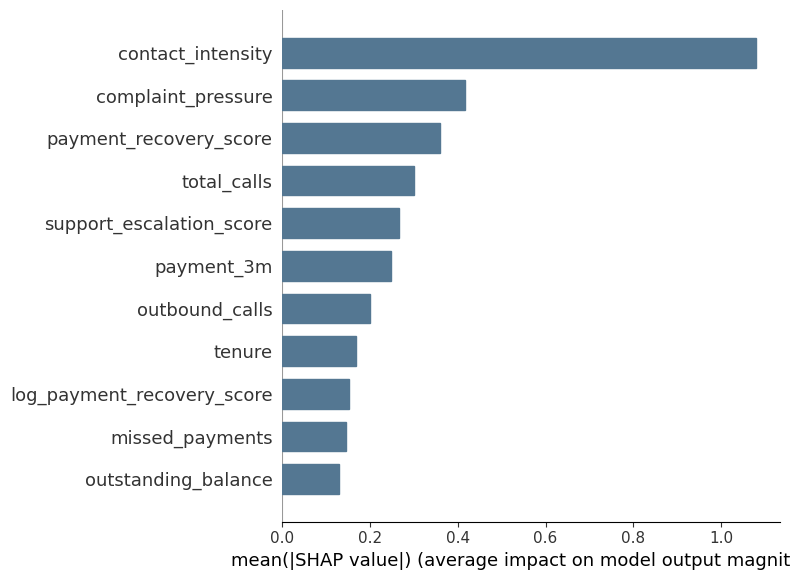

In [229]:
import matplotlib.pyplot as plt

shap.summary_plot(
    shap_values_full,
    X_full,
    plot_type="bar",
    max_display=11,
    show=False
)

ax = plt.gca()

for bar in ax.patches:
    bar.set_color("#547792")

plt.show()

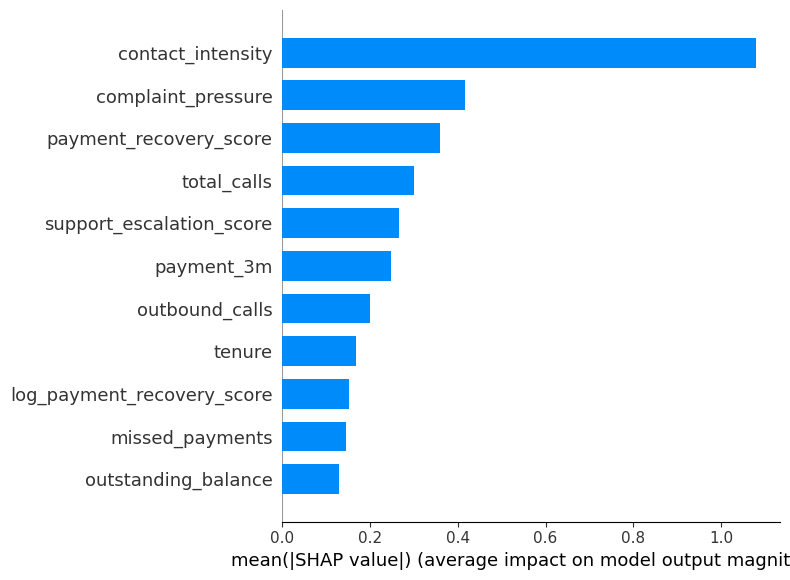

In [224]:
shap.summary_plot(
    shap_values_full,
    X_full,
    plot_type="bar",
    max_display=11
)

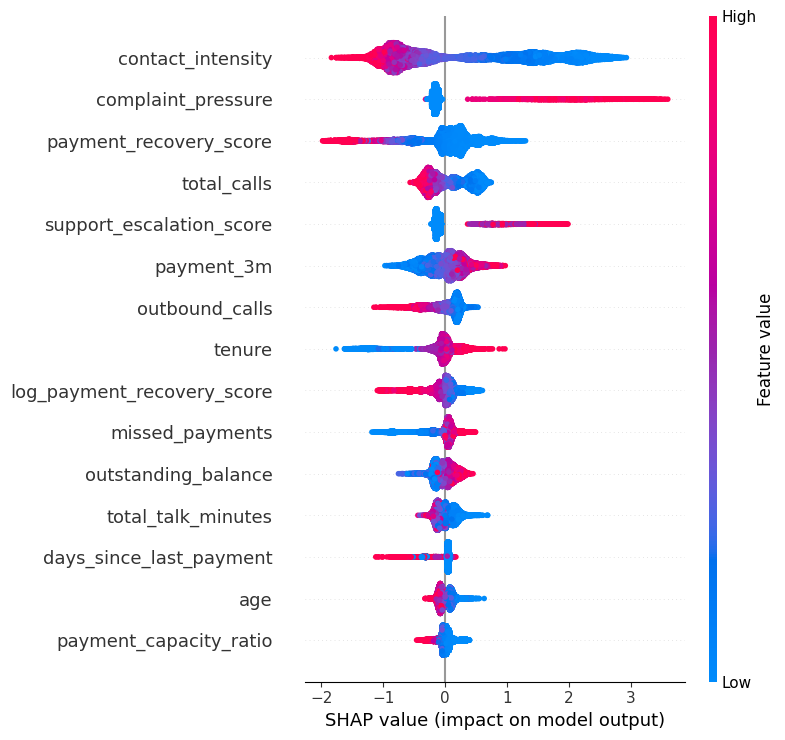

In [233]:
shap.summary_plot(
    shap_values_full,
    X_full,
    max_display=15
)

In [238]:
import pandas as pd

# Calculate mean absolute SHAP importance
shap_importance = pd.DataFrame({
    "Feature": X_full.columns,
    "SHAP Importance": abs(shap_values_full).mean(axis=0)
})

# Sort from highest to lowest
shap_importance = shap_importance.sort_values(
    by="SHAP Importance",
    ascending=False
)

# Display top 15 features
shap_importance.head(100)

,Feature,SHAP Importance
39,contact_intensity,1.080417
30,complaint_pressure,0.416291
22,payment_recovery_score,0.359421
11,total_calls,0.299446
31,support_escalation_score,0.265965
6,payment_3m,0.248624
12,outbound_calls,0.199328
0,tenure,0.168572
23,log_payment_recovery_score,0.152578
4,missed_payments,0.145273


In [219]:
import shap

shap.initjs()

customer_index = 0

shap.force_plot(
    explainer.expected_value,
    shap_values_full[customer_index],
    X_full.iloc[customer_index]
)

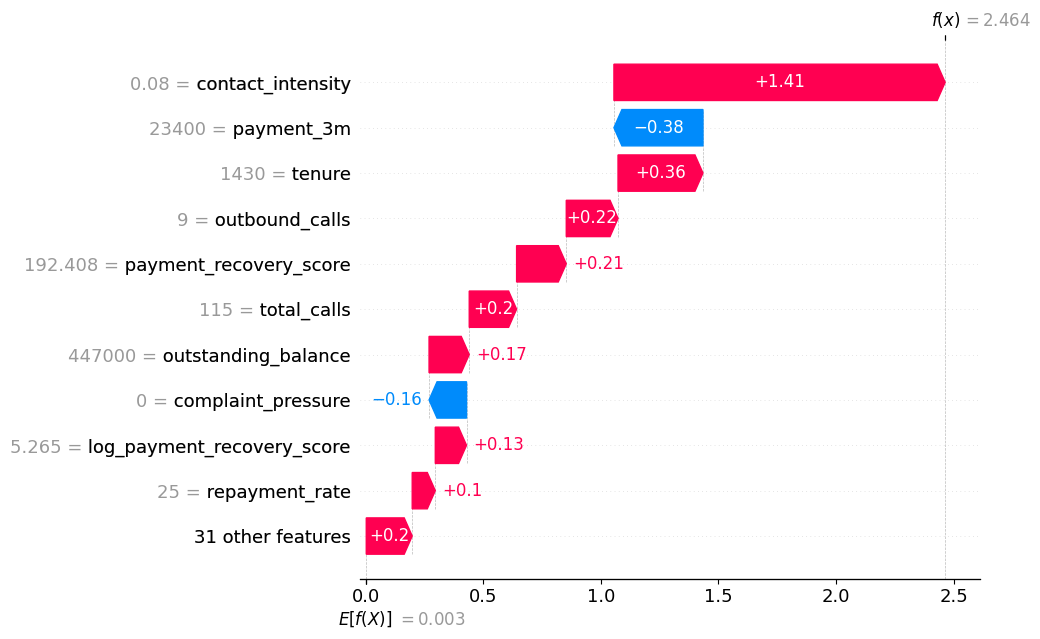

In [235]:
# Select a high-risk customer
high_risk_index = model_data_fe['churn_probability'].idxmax()

# SHAP waterfall plot
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_full[high_risk_index],
        base_values=explainer.expected_value,
        data=X_full.iloc[high_risk_index],
        feature_names=X_full.columns
    ),
    max_display=11
)

In [231]:
shap_importance = pd.DataFrame({
    'Feature': X_full.columns,
    'Mean_SHAP_Importance': np.abs(shap_values_full).mean(axis=0)
})

shap_importance = (
    shap_importance
    .sort_values(
        'Mean_SHAP_Importance',
        ascending=False
    )
)

shap_importance.head(11)

,Feature,Mean_SHAP_Importance
39,contact_intensity,1.080417
30,complaint_pressure,0.416291
22,payment_recovery_score,0.359421
11,total_calls,0.299446
31,support_escalation_score,0.265965
6,payment_3m,0.248624
12,outbound_calls,0.199328
0,tenure,0.168572
23,log_payment_recovery_score,0.152578
4,missed_payments,0.145273


### overall SHAP feature importance

In [193]:
shap_importance = pd.DataFrame({

    "Feature": X_full.columns,

    "Importance": np.abs(
        shap_values_full
    ).mean(axis=0)

})


shap_importance = shap_importance.sort_values(
    by="Importance",
    ascending=False
)


shap_importance.head(25)

,Feature,Importance
39,contact_intensity,1.080417
30,complaint_pressure,0.416291
22,payment_recovery_score,0.359421
11,total_calls,0.299446
31,support_escalation_score,0.265965
6,payment_3m,0.248624
12,outbound_calls,0.199328
0,tenure,0.168572
23,log_payment_recovery_score,0.152578
4,missed_payments,0.145273


In [167]:
shap_df = pd.DataFrame(
    shap_values_full,
    columns=X_full.columns
)

shap_df.head()

,tenure,total_amount_paid,outstanding_balance,repayment_rate,missed_payments,age,payment_3m,avg_payment_3m,payment_trend_3m,volatility_3m,last_paid_amount,total_calls,outbound_calls,received_calls,unanswered_calls,ivr_calls,csat_calls,total_talk_minutes,repossession_tickets,followup_tickets,gender_male,payment_decline_rate,payment_recovery_score,log_payment_recovery_score,payment_momentum,log_payment_momentum,missed_payment_rate,financial_stress_index,customer_value,log_customer_value,complaint_pressure,support_escalation_score,payment_stability_score,balance_pressure,payment_capacity_ratio,csat_engagement_rate,days_since_last_payment,payment_deterioration_score,recovery_after_missed_payment,contact_intensity,log_recovery_after_missed_payment
0,0.323735,0.013985,0.087363,-0.010238,0.095916,0.093604,-0.180735,0.033707,-0.019596,0.129604,0.017804,-0.276964,-0.153014,-0.054275,-0.002417,0.080706,0.000636,0.021305,0.001761,0.000269,-0.034412,0.001076,0.121682,0.000501,0.099210,-0.010169,0.026062,0.025670,0.039870,0.001494,-0.170840,-0.131040,-0.024923,0.024249,0.019410,0.037122,0.059324,-0.002454,-0.021895,-1.053421,-0.059362
1,0.164551,-0.060731,-0.137129,-0.006365,-0.021275,-0.042308,0.102925,0.047874,0.005902,0.030015,0.017470,-0.240101,-0.352037,-0.071088,-0.012627,-0.026098,0.000593,-0.114907,0.000098,0.000353,-0.024034,-0.015247,-0.087345,-0.106900,-0.014288,0.021933,-0.083040,-0.022705,-0.125260,-0.023560,-0.184879,-0.166717,0.018775,-0.014878,-0.018987,0.027390,0.068231,-0.024013,0.028926,-0.711798,0.046090
2,-0.083655,0.055811,0.187339,0.013702,0.116625,0.209884,0.001763,-0.031378,0.078346,-0.177810,-0.012173,0.120721,-0.206288,-0.067745,0.007260,-0.028226,0.000371,-0.086226,0.000937,0.000214,-0.048138,0.021247,0.289977,0.071254,-0.007908,-0.003511,0.074044,0.112964,0.033343,0.001102,-0.176699,-0.123337,0.050888,0.034305,0.068979,0.028558,0.052030,-0.090339,0.018742,0.630211,-0.034841
3,-0.007268,-0.069647,-0.054557,0.008511,0.038201,-0.015863,0.444260,-0.027297,0.020340,0.005173,0.018369,-0.267096,-0.636223,-0.062142,0.014593,0.016319,0.000318,-0.216997,0.016804,0.016061,-0.008706,0.004143,-0.039451,-0.056334,-0.015318,0.023483,-0.016465,-0.021611,-0.073920,0.000885,3.073133,1.763556,0.020147,0.013763,-0.014093,0.018165,0.055672,0.054123,0.051024,-0.633069,0.081306
4,0.335664,0.047764,0.132592,0.044165,0.093047,-0.113345,-0.226656,0.036094,-0.017557,0.043914,-0.003147,0.320037,0.212329,0.008345,-0.031432,-0.033795,0.000451,0.214455,-0.003371,0.001398,-0.057653,-0.009370,0.193872,0.094083,0.089806,0.050535,0.046343,0.056222,0.052901,0.014146,-0.143272,0.677695,-0.007927,0.060920,0.080482,0.020508,0.053198,0.106786,0.028712,1.361212,-0.018273


In [211]:
### key visuals

### 3 SHAP features per customer

In [168]:
def get_top_shap_features(row, top_n=3):
    
    top_features = (
        row.abs()
        .sort_values(
            ascending=False
        )
        .head(top_n)
        .index
        .tolist()
    )
    
    return ", ".join(top_features)


model_data_fe['top_shap_features'] = (
    shap_df.apply(
        get_top_shap_features,
        axis=1
    )
)

In [169]:
model_data_fe[
    [
        'customer_id',
        'risk_category',
        'top_shap_features'
    ]
].head()

,customer_id,risk_category,top_shap_features
0,GBEFDJG,Low Risk,"contact_intensity, tenure, total_calls"
1,GBAGFBB,Low Risk,"contact_intensity, outbound_calls, total_calls"
2,GEJGIFG,High Risk,"contact_intensity, payment_recovery_score, age"
3,GEEDDAC,High Risk,"complaint_pressure, support_escalation_score, ..."
4,GBBDGBC,High Risk,"contact_intensity, support_escalation_score, t..."


### Defining the feature meanings

In [194]:
feature_meanings = {

    'contact_intensity': {
        'High Risk': 'Reduced customer engagement compared to active customers',
        'Medium Risk': 'Customer interaction pattern requires monitoring',
        'Low Risk': 'Strong customer engagement through regular interactions'
    },

    'complaint_pressure': {
        'High Risk': 'High complaint activity indicating dissatisfaction',
        'Medium Risk': 'Emerging customer concerns requiring attention',
        'Low Risk': 'Low complaint activity indicating positive experience'
    },

    'payment_recovery_score': {
        'High Risk': 'Weak recovery after missed payments',
        'Medium Risk': 'Unstable payment recovery behaviour',
        'Low Risk': 'Good recovery after payment challenges'
    },

    'total_calls': {
        'High Risk': 'Low customer interaction activity indicating disengagement',
        'Medium Risk': 'Moderate customer interaction requiring monitoring',
        'Low Risk': 'High customer engagement through communication'
    },

    'support_escalation_score': {
        'High Risk': 'Unresolved support issues and escalations',
        'Medium Risk': 'Increasing support issues requiring follow-up',
        'Low Risk': 'Low support escalation levels'
    },

    'payment_3m': {
        'High Risk': 'Low recent payment activity',
        'Medium Risk': 'Declining recent payment activity',
        'Low Risk': 'Strong recent payment activity'
    },

    'outbound_calls': {
        'High Risk': 'Limited proactive customer communication',
        'Medium Risk': 'Moderate customer outreach activity',
        'Low Risk': 'Strong proactive customer engagement'
    },

    'tenure': {
        'High Risk': 'Short customer relationship period increasing retention risk',
        'Medium Risk': 'Moderate customer relationship requiring engagement',
        'Low Risk': 'Established customer relationship'
    },

    'log_payment_recovery_score': {
        'High Risk': 'Poor payment recovery pattern after challenges',
        'Medium Risk': 'Inconsistent recovery behaviour',
        'Low Risk': 'Stable payment recovery behaviour'
    },

    'missed_payments': {
        'High Risk': 'Frequent missed payments indicating repayment difficulty',
        'Medium Risk': 'Some missed payments requiring monitoring',
        'Low Risk': 'Consistent payment behaviour'
    },

    'outstanding_balance': {
        'High Risk': 'High outstanding balance increasing churn exposure',
        'Medium Risk': 'Moderate outstanding balance requiring monitoring',
        'Low Risk': 'Manageable outstanding balance'
    },

    'total_talk_minutes': {
        'High Risk': 'Low communication engagement with customers',
        'Medium Risk': 'Moderate communication engagement',
        'Low Risk': 'Strong communication engagement'
    },

    'days_since_last_payment': {
        'High Risk': 'Long period since last payment indicating disengagement',
        'Medium Risk': 'Increasing payment inactivity requiring follow-up',
        'Low Risk': 'Recent payment activity maintained'
    },

    'age': {
        'High Risk': 'Customer demographic profile associated with higher churn tendency',
        'Medium Risk': 'Customer demographic profile requiring monitoring',
        'Low Risk': 'Customer demographic profile associated with stable retention'
    },

    'payment_capacity_ratio': {
        'High Risk': 'Low ability to meet payment obligations',
        'Medium Risk': 'Moderate repayment capacity pressure',
        'Low Risk': 'Strong repayment capacity'
    },

    'payment_momentum': {
        'High Risk': 'Declining payment momentum',
        'Medium Risk': 'Unstable payment momentum',
        'Low Risk': 'Positive payment momentum'
    },

    'missed_payment_rate': {
        'High Risk': 'High proportion of missed payments',
        'Medium Risk': 'Moderate missed payment frequency',
        'Low Risk': 'Reliable payment consistency'
    },

    'customer_value': {
        'High Risk': 'Declining customer value increasing retention concerns',
        'Medium Risk': 'Moderate customer value requiring attention',
        'Low Risk': 'High customer value contribution'
    },

    'csat_engagement_rate': {
        'High Risk': 'Low satisfaction engagement indicating experience concerns',
        'Medium Risk': 'Moderate satisfaction engagement',
        'Low Risk': 'Positive satisfaction engagement'
    },

    'ivr_calls': {
        'High Risk': 'Low automated interaction engagement',
        'Medium Risk': 'Moderate IVR interaction activity',
        'Low Risk': 'Active customer interaction through IVR channels'
    },

    'volatility_3m': {
        'High Risk': 'High payment volatility indicating unstable repayment patterns',
        'Medium Risk': 'Moderate payment fluctuations',
        'Low Risk': 'Stable payment behaviour'
    },

    'log_recovery_after_missed_payment': {
        'High Risk': 'Poor recovery after missed payment events',
        'Medium Risk': 'Slow recovery after payment challenges',
        'Low Risk': 'Strong recovery after missed payments'
    },

    'repayment_rate': {
        'High Risk': 'Low repayment rate indicating financial pressure',
        'Medium Risk': 'Moderate repayment performance',
        'Low Risk': 'Strong repayment consistency'
    },

    'payment_decline_rate': {
        'High Risk': 'Frequent payment declines indicating financial difficulty',
        'Medium Risk': 'Increasing payment decline behaviour',
        'Low Risk': 'Stable successful payment pattern'
    },

    'gender_male': {
        'High Risk': 'Customer demographic factor associated with higher observed churn risk',
        'Medium Risk': 'Customer demographic factor requiring monitoring',
        'Low Risk': 'Customer demographic factor associated with stable retention'
    }

}

In [195]:
model_data_fe['top_shap_features'].isna().sum()

0

In [196]:
model_data_fe = model_data_fe.dropna(
    subset=['top_shap_features']
)

In [197]:
def get_top_shap_features(row, top_n=4):

    top_features = (
        row.abs()
        .sort_values(
            ascending=False
        )
        .head(top_n)
        .index
        .tolist()
    )

    return ", ".join(top_features)


model_data_fe['top_shap_features'] = (
    shap_df.apply(
        get_top_shap_features,
        axis=1
    )
)

In [198]:
model_data_fe[
    [
        'customer_id',
        'risk_category',
        'top_shap_features'
    ]
].head()

,customer_id,risk_category,top_shap_features
0,GBEFDJG,Low Risk,"contact_intensity, tenure, total_calls, paymen..."
1,GBAGFBB,Low Risk,"contact_intensity, outbound_calls, total_calls..."
2,GEJGIFG,High Risk,"contact_intensity, payment_recovery_score, age..."
3,GEEDDAC,High Risk,"complaint_pressure, support_escalation_score, ..."
4,GBBDGBC,High Risk,"contact_intensity, support_escalation_score, t..."


In [199]:
def generate_explanation(row):

    features = row['top_shap_features'].split(', ')
    risk = row['risk_category']

    explanations = []

    for feature in features:

        if feature in feature_meanings:
            explanations.append(
                feature_meanings[feature][risk]
            )

    return "; ".join(explanations)


model_data_fe['churn_driver_explanation'] = (
    model_data_fe.apply(
        generate_explanation,
        axis=1
    )
)

In [200]:
model_data_fe[
    [
        'customer_id',
        'risk_category',
        'top_shap_features',
        'churn_driver_explanation'
    ]
].head()

,customer_id,risk_category,top_shap_features,churn_driver_explanation
0,GBEFDJG,Low Risk,"contact_intensity, tenure, total_calls, paymen...",Strong customer engagement through regular int...
1,GBAGFBB,Low Risk,"contact_intensity, outbound_calls, total_calls...",Strong customer engagement through regular int...
2,GEJGIFG,High Risk,"contact_intensity, payment_recovery_score, age...",Reduced customer engagement compared to active...
3,GEEDDAC,High Risk,"complaint_pressure, support_escalation_score, ...",High complaint activity indicating dissatisfac...
4,GBBDGBC,High Risk,"contact_intensity, support_escalation_score, t...",Reduced customer engagement compared to active...


In [201]:
prescriptive_actions = {

    'contact_intensity': {
        'High Risk': 'Initiate proactive customer engagement and investigate reasons for reduced interaction.',
        'Medium Risk': 'Schedule targeted follow-up to strengthen customer engagement.',
        'Low Risk': 'Maintain regular customer communication.'
    },

    'complaint_pressure': {
        'High Risk': 'Prioritize complaint resolution and address customer dissatisfaction.',
        'Medium Risk': 'Follow up on customer concerns before escalation.',
        'Low Risk': 'Maintain service quality and monitor satisfaction.'
    },

    'payment_recovery_score': {
        'High Risk': 'Provide payment recovery support and discuss flexible repayment options.',
        'Medium Risk': 'Monitor repayment recovery progress and provide reminders.',
        'Low Risk': 'Maintain current repayment support approach.'
    },

    'total_calls': {
        'High Risk': 'Reconnect with customer and identify causes of reduced communication.',
        'Medium Risk': 'Increase proactive communication frequency.',
        'Low Risk': 'Maintain current engagement activities.'
    },

    'support_escalation_score': {
        'High Risk': 'Assign priority support intervention to resolve outstanding issues.',
        'Medium Risk': 'Review support cases and provide timely resolution.',
        'Low Risk': 'Continue standard support monitoring.'
    },

    'payment_3m': {
        'High Risk': 'Investigate recent payment decline and provide retention support.',
        'Medium Risk': 'Encourage consistent recent payments through reminders.',
        'Low Risk': 'Maintain positive payment behaviour.'
    },

    'outbound_calls': {
        'High Risk': 'Increase proactive outreach to reconnect with customer.',
        'Medium Risk': 'Schedule additional follow-up communication.',
        'Low Risk': 'Maintain normal customer outreach.'
    },

    'tenure': {
        'High Risk': 'Strengthen relationship with newer customers through targeted retention activities.',
        'Medium Risk': 'Increase engagement to improve customer loyalty.',
        'Low Risk': 'Maintain relationship with established customers.'
    },

    'log_payment_recovery_score': {
        'High Risk': 'Provide additional recovery assistance after payment challenges.',
        'Medium Risk': 'Monitor recovery behaviour and provide payment guidance.',
        'Low Risk': 'Continue supporting positive recovery behaviour.'
    },

    'missed_payments': {
        'High Risk': 'Investigate payment barriers and offer flexible repayment solutions.',
        'Medium Risk': 'Monitor missed payments and send early reminders.',
        'Low Risk': 'Continue reinforcing good payment behaviour.'
    },

    'outstanding_balance': {
        'High Risk': 'Engage customer on repayment plans to reduce outstanding balance.',
        'Medium Risk': 'Monitor balance growth and provide payment guidance.',
        'Low Risk': 'Maintain current repayment relationship.'
    },

    'total_talk_minutes': {
        'High Risk': 'Increase meaningful customer conversations and engagement efforts.',
        'Medium Risk': 'Monitor communication quality and improve follow-up.',
        'Low Risk': 'Maintain strong customer communication.'
    },

    'days_since_last_payment': {
        'High Risk': 'Contact customer immediately regarding payment inactivity.',
        'Medium Risk': 'Follow up on delayed payments and encourage repayment.',
        'Low Risk': 'Maintain normal payment monitoring.'
    },

    'age': {
        'High Risk': 'Apply targeted retention support based on customer needs.',
        'Medium Risk': 'Monitor customer engagement patterns.',
        'Low Risk': 'Maintain existing customer relationship strategy.'
    },

    'payment_capacity_ratio': {
        'High Risk': 'Assess affordability challenges and provide repayment support.',
        'Medium Risk': 'Monitor payment capacity and financial pressure.',
        'Low Risk': 'Maintain current repayment approach.'
    },

    'payment_momentum': {
        'High Risk': 'Intervene early to reverse declining payment behaviour.',
        'Medium Risk': 'Encourage consistent payment patterns.',
        'Low Risk': 'Maintain positive payment momentum.'
    },

    'missed_payment_rate': {
        'High Risk': 'Develop repayment intervention plan for frequent missed payments.',
        'Medium Risk': 'Monitor missed payment trends and provide reminders.',
        'Low Risk': 'Maintain reliable payment behaviour.'
    },

    'customer_value': {
        'High Risk': 'Prioritize retention activities for valuable customers showing risk.',
        'Medium Risk': 'Strengthen engagement to maintain customer value.',
        'Low Risk': 'Maintain customer relationship and loyalty.'
    },

    'csat_engagement_rate': {
        'High Risk': 'Address customer experience issues and improve satisfaction.',
        'Medium Risk': 'Monitor satisfaction trends and follow up where needed.',
        'Low Risk': 'Maintain positive customer experience.'
    },

    'ivr_calls': {
        'High Risk': 'Investigate reduced IVR engagement and reconnect customer.',
        'Medium Risk': 'Monitor IVR interaction patterns.',
        'Low Risk': 'Maintain current self-service engagement.'
    },

    'volatility_3m': {
        'High Risk': 'Investigate unstable payment patterns and provide support.',
        'Medium Risk': 'Monitor payment fluctuations closely.',
        'Low Risk': 'Maintain stable payment behaviour.'
    },

    'log_recovery_after_missed_payment': {
        'High Risk': 'Provide additional recovery support after missed payments.',
        'Medium Risk': 'Monitor repayment recovery progress.',
        'Low Risk': 'Maintain effective recovery strategy.'
    },

    'repayment_rate': {
        'High Risk': 'Engage customer to improve repayment consistency.',
        'Medium Risk': 'Monitor repayment performance and provide reminders.',
        'Low Risk': 'Maintain strong repayment behaviour.'
    },

    'payment_decline_rate': {
        'High Risk': 'Investigate payment failures and provide payment assistance.',
        'Medium Risk': 'Monitor decline patterns and encourage successful payments.',
        'Low Risk': 'Maintain successful payment behaviour.'
    },

    'gender_male': {
        'High Risk': 'Apply standard retention support based on individual customer behaviour.',
        'Medium Risk': 'Monitor engagement and payment patterns.',
        'Low Risk': 'Continue standard customer relationship management.'
    }

}

In [202]:
def generate_action(row):

    features = row['top_shap_features'].split(', ')
    risk = row['risk_category']

    actions = []

    for feature in features:

        if feature in prescriptive_actions:
            actions.append(
                prescriptive_actions[feature][risk]
            )

    return "; ".join(actions)


model_data_fe['recommended_action'] = (
    model_data_fe.apply(
        generate_action,
        axis=1
    )
)

In [203]:
model_data_fe[
    [
        'customer_id',
        'risk_category',
        'top_shap_features',
        'churn_driver_explanation',
        'recommended_action'
    ]
].head()

,customer_id,risk_category,top_shap_features,churn_driver_explanation,recommended_action
0,GBEFDJG,Low Risk,"contact_intensity, tenure, total_calls, paymen...",Strong customer engagement through regular int...,Maintain regular customer communication.; Main...
1,GBAGFBB,Low Risk,"contact_intensity, outbound_calls, total_calls...",Strong customer engagement through regular int...,Maintain regular customer communication.; Main...
2,GEJGIFG,High Risk,"contact_intensity, payment_recovery_score, age...",Reduced customer engagement compared to active...,Initiate proactive customer engagement and inv...
3,GEEDDAC,High Risk,"complaint_pressure, support_escalation_score, ...",High complaint activity indicating dissatisfac...,Prioritize complaint resolution and address cu...
4,GBBDGBC,High Risk,"contact_intensity, support_escalation_score, t...",Reduced customer engagement compared to active...,Initiate proactive customer engagement and inv...


In [204]:
dashboard_df = model_data_fe[
    [
        'customer_id',
        'churn_probability',
        'risk_score',
        'risk_category',
        'top_shap_features',
        'churn_driver_explanation',
        'recommended_action',
        'repayment_rate',
        'missed_payments',
        'outstanding_balance',
        'total_calls',
        'outbound_calls',
        'repossession_tickets',
        'followup_tickets',
        'tenure',
        'age',
        'gender_male'
    ]
].copy()

In [205]:
dashboard_df.head()

,customer_id,churn_probability,risk_score,risk_category,top_shap_features,churn_driver_explanation,recommended_action,repayment_rate,missed_payments,outstanding_balance,total_calls,outbound_calls,repossession_tickets,followup_tickets,tenure,age,gender_male
0,GBEFDJG,0.300046,30.004635,Low Risk,"contact_intensity, tenure, total_calls, paymen...",Strong customer engagement through regular int...,Maintain regular customer communication.; Main...,54,470,365200,497,30,0.0,0,1413,33.0,True
1,GBAGFBB,0.106731,10.673128,Low Risk,"contact_intensity, outbound_calls, total_calls...",Strong customer engagement through regular int...,Maintain regular customer communication.; Main...,77,253,181955,320,44,0.0,0,1398,57.0,True
2,GEJGIFG,0.751188,75.118790,High Risk,"contact_intensity, payment_recovery_score, age...",Reduced customer engagement compared to active...,Initiate proactive customer engagement and inv...,26,727,494700,123,29,0.0,0,1201,34.0,True
3,GEEDDAC,0.971388,97.138824,High Risk,"complaint_pressure, support_escalation_score, ...",High complaint activity indicating dissatisfac...,Prioritize complaint resolution and address cu...,76,246,192246,350,75,0.0,0,1251,48.0,True
4,GBBDGBC,0.978427,97.842682,High Risk,"contact_intensity, support_escalation_score, t...",Reduced customer engagement compared to active...,Initiate proactive customer engagement and inv...,24,751,450450,106,2,1.0,0,1421,76.0,True


In [206]:
dashboard_df.shape

(26183, 17)

In [207]:
dashboard_df.isna().sum()

customer_id                 0
churn_probability           0
risk_score                  0
risk_category               0
top_shap_features           0
churn_driver_explanation    0
recommended_action          0
repayment_rate              0
missed_payments             0
outstanding_balance         0
total_calls                 0
outbound_calls              0
repossession_tickets        0
followup_tickets            0
tenure                      0
age                         0
gender_male                 0
dtype: int64

customer_id                 0
churn_probability           0
risk_score                  0
risk_category               0
top_shap_features           0
churn_driver_explanation    0
recommended_action          0
repayment_rate              0
missed_payments             0
outstanding_balance         0
total_calls                 0
outbound_calls              0
repossession_tickets        0
followup_tickets            0
tenure                      0
age                         0
gender_male                 0
dtype: int64

In [208]:
# Save dashboard data

dashboard_df.to_csv(
    "customer_churn_dashboard.csv",
    index=False
)

dashboard_df.to_pickle(
    "customer_churn_dashboard.pkl"
)

In [209]:
import os

print(
    os.path.exists("customer_churn_dashboard.csv")
)

print(
    os.path.exists("customer_churn_dashboard.pkl")
)

True
True


In [210]:
dashboard_df[
    dashboard_df['customer_id'] == 'GBEFDJG'
]

,customer_id,churn_probability,risk_score,risk_category,top_shap_features,churn_driver_explanation,recommended_action,repayment_rate,missed_payments,outstanding_balance,total_calls,outbound_calls,repossession_tickets,followup_tickets,tenure,age,gender_male
0,GBEFDJG,0.300046,30.004635,Low Risk,"contact_intensity, tenure, total_calls, paymen...",Strong customer engagement through regular int...,Maintain regular customer communication.; Main...,54,470,365200,497,30,0.0,0,1413,33.0,True


In [242]:
# Create dashboard export dataset

dashboard_data = X_test.copy()

# Add customer ID
dashboard_data["customer_id"] = customer_ids.loc[X_test.index].values

# Actual churn
dashboard_data["actual_churn"] = y_test.values

# Predicted probability
dashboard_data["churn_probability"] = (
    final_model.predict_proba(X_test)[:,1]
)

# Predicted class
dashboard_data["predicted_churn"] = (
    final_model.predict(X_test)
)

# Risk category
dashboard_data["risk_level"] = pd.cut(
    dashboard_data["churn_probability"],
    bins=[0,0.3,0.7,1],
    labels=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ]
)

dashboard_data.head()

,tenure,total_amount_paid,outstanding_balance,repayment_rate,missed_payments,age,payment_3m,avg_payment_3m,payment_trend_3m,volatility_3m,last_paid_amount,total_calls,outbound_calls,received_calls,unanswered_calls,ivr_calls,csat_calls,total_talk_minutes,repossession_tickets,followup_tickets,gender_male,payment_decline_rate,payment_recovery_score,log_payment_recovery_score,payment_momentum,log_payment_momentum,missed_payment_rate,financial_stress_index,customer_value,log_customer_value,complaint_pressure,support_escalation_score,payment_stability_score,balance_pressure,payment_capacity_ratio,csat_engagement_rate,days_since_last_payment,payment_deterioration_score,recovery_after_missed_payment,contact_intensity,log_recovery_after_missed_payment,customer_id,actual_churn,churn_probability,predicted_churn,risk_level
1253,1218,282000,390000,42,582,23.0,107000.0,11888.888890,35500.0,10447.694530,4500.0,69,13,0,0,0,0,6.2000,0.0,0,True,-7.999327,483.704974,6.183540,1491000.0,14.214958,0.477441,1.637797,11844000,16.287332,0.00082,1.0,0.000096,1.382974,0.723075,0.0,1095,-3.819203,183.533448,0.056604,5.217831,GECFHJG,1,0.995229,1,High Risk
22022,1275,467909,126091,79,256,53.0,54000.0,10800.000000,6000.0,2400.000000,12000.0,225,47,6,9,4,0,90.1000,0.0,0,True,-3.999630,1820.657588,7.507502,474000.0,13.068965,0.200627,0.622901,36964811,17.425477,0.00000,0.0,0.000416,0.269477,3.710854,0.0,1095,-0.802434,210.116732,0.176332,5.352411,GEBBIAC,0,0.100142,0,Low Risk
11783,1250,187900,406100,32,689,56.0,49400.0,2147.826087,4200.0,1057.013663,3600.0,26,0,0,0,0,0,0.0000,0.0,0,False,-21.989762,272.318841,5.610639,134400.0,11.808583,0.550759,1.914428,6012800,15.609401,0.00000,0.0,0.000945,2.161244,0.462693,0.0,1095,-12.111068,71.594203,0.020783,4.284885,GEEJFJJ,1,0.987781,1,High Risk
6812,161,4231,100769,4,153,62.0,70000.0,5384.615385,4000.0,1443.204849,2000.0,159,8,0,0,0,0,8.1666,0.0,0,False,-11.997772,27.474026,3.348992,16000.0,9.680406,0.944444,2.864140,16924,9.736547,0.00000,0.0,0.000692,23.811200,0.041987,0.0,1095,-11.331229,454.545455,0.981481,6.121496,GBDDGCG,1,0.405987,0,Medium Risk
13970,1390,83600,708400,11,890,53.0,5600.0,800.000000,0.0,0.000000,800.0,111,0,0,0,0,0,0.0000,0.0,0,False,-5.992509,93.827160,4.552056,0.0,0.000000,0.639827,2.424271,919600,13.731695,0.00000,0.0,1.000000,8.473583,0.118012,0.0,1095,-3.834172,6.285073,0.079799,1.985827,GBAAGCA,1,0.966164,1,High Risk


In [244]:
# ==================================================
# CREATE OPERATIONAL CUSTOMER DECISION DATASET
# ==================================================

dashboard_data = X_test.copy()


# Add customer information

dashboard_data["customer_id"] = (
    customer_ids.loc[X_test.index].values
)


dashboard_data["actual_churn"] = (
    y_test.values
)


# ==================================================
# MODEL PREDICTIONS
# ==================================================

dashboard_data["churn_probability"] = (
    final_model.predict_proba(X_test)[:,1]
)


dashboard_data["risk_score"] = (
    dashboard_data["churn_probability"] * 100
).round(2)


dashboard_data["predicted_churn"] = (
    final_model.predict(X_test)
)



# Risk categories

def assign_risk(prob):

    if prob < 0.3:
        return "Low Risk"

    elif prob < 0.7:
        return "Medium Risk"

    else:
        return "High Risk"



dashboard_data["risk_category"] = (
    dashboard_data["churn_probability"]
    .apply(assign_risk)
)



# ==================================================
# SHAP EXPLANATION
# ==================================================

shap_output = explainer(
    X_test
)



def get_customer_explanation(index):

    values = pd.DataFrame({

        "feature": model_features,

        "shap_value":
        shap_output.values[index]

    })


    # strongest contributors

    values["impact"] = (
        values["shap_value"]
        .abs()
    )


    top = (
        values
        .sort_values(
            "impact",
            ascending=False
        )
        .head(5)
    )


    explanations=[]
    actions=[]


    risk = dashboard_data.iloc[index]["risk_category"]



    for feature in top["feature"]:


        # check if feature exists in dictionary

        if feature in feature_meanings:


            explanations.append(
                feature_meanings[feature][risk]
            )


            actions.append(
                prescriptive_actions[feature][risk]
            )



    return (
        "; ".join(explanations),
        "; ".join(actions),
        ", ".join(top["feature"])
    )



results = [
    get_customer_explanation(i)
    for i in range(len(X_test))
]



dashboard_data[
    [
        "churn_driver_explanation",
        "recommended_action",
        "top_shap_features"
    ]
] = pd.DataFrame(
    results,
    index=dashboard_data.index
)



# ==================================================
# SELECT DASHBOARD COLUMNS
# ==================================================

dashboard_data = dashboard_data[
[
"customer_id",

"churn_probability",
"risk_score",
"risk_category",

"top_shap_features",

"churn_driver_explanation",

"recommended_action",


# payment behaviour

"repayment_rate",
"missed_payments",
"missed_payment_rate",
"payment_recovery_score",
"payment_momentum",

"outstanding_balance",
"payment_capacity_ratio",


# engagement

"contact_intensity",
"total_calls",
"outbound_calls",
"total_talk_minutes",

"complaint_pressure",
"support_escalation_score",


# customer profile

"tenure",
"age",
"gender_male"

]

]


dashboard_data.head()

,customer_id,churn_probability,risk_score,risk_category,top_shap_features,churn_driver_explanation,recommended_action,repayment_rate,missed_payments,missed_payment_rate,payment_recovery_score,payment_momentum,outstanding_balance,payment_capacity_ratio,contact_intensity,total_calls,outbound_calls,total_talk_minutes,complaint_pressure,support_escalation_score,tenure,age,gender_male
1253,GECFHJG,0.995229,99.519997,High Risk,"contact_intensity, complaint_pressure, support...",Reduced customer engagement compared to active...,Initiate proactive customer engagement and inv...,42,582,0.477441,483.704974,1491000.0,390000,0.723075,0.056604,69,13,6.2000,0.00082,1.0,1218,23.0,True
22022,GEBBIAC,0.100142,10.010000,Low Risk,"contact_intensity, outbound_calls, total_talk_...",Strong customer engagement through regular int...,Maintain regular customer communication.; Main...,79,256,0.200627,1820.657588,474000.0,126091,3.710854,0.176332,225,47,90.1000,0.00000,0.0,1275,53.0,True
11783,GEEJFJJ,0.987781,98.779999,High Risk,"contact_intensity, total_calls, payment_recove...",Reduced customer engagement compared to active...,Initiate proactive customer engagement and inv...,32,689,0.550759,272.318841,134400.0,406100,0.462693,0.020783,26,0,0.0000,0.00000,0.0,1250,56.0,False
6812,GBDDGCG,0.405987,40.599998,Medium Risk,"contact_intensity, payment_recovery_score, ten...",Customer interaction pattern requires monitori...,Schedule targeted follow-up to strengthen cust...,4,153,0.944444,27.474026,16000.0,100769,0.041987,0.981481,159,8,8.1666,0.00000,0.0,161,62.0,False
13970,GBAAGCA,0.966164,96.620003,High Risk,"contact_intensity, payment_recovery_score, pay...",Reduced customer engagement compared to active...,Initiate proactive customer engagement and inv...,11,890,0.639827,93.827160,0.0,708400,0.118012,0.079799,111,0,0.0000,0.00000,0.0,1390,53.0,False


In [246]:
dashboard_data.shape

(5315, 23)

In [245]:
import os

# Create data folder if it does not exist
os.makedirs("data", exist_ok=True)


# Save customer dashboard dataset
dashboard_data.to_csv(
    "data/customer_predictions.csv",
    index=False
)


print("Saved successfully!")
print(dashboard_data.shape)

Saved successfully!
(5315, 23)


In [247]:
# ==========================================
# CREATE FULL CUSTOMER DASHBOARD DATASET
# ==========================================


# Use all customers
dashboard_data = X_full.copy()


# Add customer ID
dashboard_data["customer_id"] = (
    customer_ids.loc[X_full.index].values
)



# Add actual churn label
dashboard_data["actual_churn"] = (
    y.loc[X_full.index].values
)



# Predict probability for all customers
dashboard_data["churn_probability"] = (
    final_model.predict_proba(X_full)[:,1]
)



# Predicted churn
dashboard_data["predicted_churn"] = (
    final_model.predict(X_full)
)



# Risk score
dashboard_data["risk_score"] = (
    dashboard_data["churn_probability"] * 100
).round(2)



# Risk category

dashboard_data["risk_category"] = pd.cut(
    
    dashboard_data["churn_probability"],

    bins=[
        0,
        0.3,
        0.7,
        1
    ],

    labels=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ],

    include_lowest=True

)



dashboard_data.head()

,tenure,total_amount_paid,outstanding_balance,repayment_rate,missed_payments,age,payment_3m,avg_payment_3m,payment_trend_3m,volatility_3m,last_paid_amount,total_calls,outbound_calls,received_calls,unanswered_calls,ivr_calls,csat_calls,total_talk_minutes,repossession_tickets,followup_tickets,gender_male,payment_decline_rate,payment_recovery_score,log_payment_recovery_score,payment_momentum,log_payment_momentum,missed_payment_rate,financial_stress_index,customer_value,log_customer_value,complaint_pressure,support_escalation_score,payment_stability_score,balance_pressure,payment_capacity_ratio,csat_engagement_rate,days_since_last_payment,payment_deterioration_score,recovery_after_missed_payment,contact_intensity,log_recovery_after_missed_payment,customer_id,actual_churn,churn_probability,predicted_churn,risk_score,risk_category
0,1413,426800,365200,54,470,33.0,39600.0,5657.142857,400.0,139.970842,5600.0,497,30,1,1,2,0,20.7500,0.0,0,True,-5.998940,906.157113,6.810316,21600.0,9.980495,0.332390,1.253501,23047200,16.953055,0.000000,0.0,0.007094,0.855668,1.168671,0.0,1095,-1.993990,84.076433,0.351485,4.443550,GBEFDJG,1,0.300046,0,30.000000,Medium Risk
1,1398,610045,181955,77,253,57.0,53000.0,5300.000000,4500.0,1268.857754,5000.0,320,44,1,1,0,0,37.8833,0.0,0,True,-8.998302,2401.751969,7.784370,346500.0,12.755641,0.180843,0.640584,46973465,17.665093,0.000000,0.0,0.000787,0.298264,3.352706,0.0,1095,-1.627284,208.661417,0.228735,5.345494,GBAGFBB,1,0.106731,0,10.670000,Low Risk
2,1201,177300,494700,26,727,34.0,53300.0,7614.285714,39300.0,13260.621460,2800.0,123,29,1,2,0,0,21.5166,0.0,0,True,-5.999212,243.543956,5.499395,1021800.0,13.837077,0.604825,2.080985,4609800,15.343695,0.000000,0.0,0.000075,2.790170,0.358398,0.0,1126,-3.628475,73.214286,0.102329,4.306957,GEJGIFG,1,0.751188,1,75.120003,High Risk
3,1251,598600,192246,76,246,48.0,85400.0,7763.636364,12800.0,3931.058781,6400.0,350,75,2,5,2,0,128.7166,0.0,0,True,-9.998712,2423.481781,7.793373,972800.0,13.787935,0.196486,0.679574,45493600,17.633082,0.001597,2.0,0.000254,0.321159,3.113703,0.0,1095,-1.964603,345.748988,0.279553,5.848601,GEEDDAC,1,0.971388,1,97.139999,High Risk
4,1421,143550,450450,24,751,76.0,32250.0,848.684210,1350.0,330.567065,1200.0,106,2,0,0,0,0,1.0833,1.0,0,True,-36.956454,190.890957,5.256927,32400.0,10.385945,0.528129,2.046461,3445200,15.052493,0.000000,1.0,0.003016,3.137909,0.318681,0.0,1095,-19.517790,42.885638,0.074543,3.781587,GBBDGBC,1,0.978427,1,97.839996,High Risk


In [248]:
dashboard_data.shape

(26575, 47)

In [249]:
# ==========================================
# ADD SHAP EXPLANATIONS
# ==========================================


# Calculate SHAP values for all customers

shap_values_full = explainer.shap_values(
    X_full
)



def get_customer_shap_reason(row_index):

    shap_row = shap_values_full[row_index]

    feature_scores = pd.DataFrame({

        "feature": X_full.columns,

        "impact": shap_row

    })


    feature_scores["abs_impact"] = (
        feature_scores["impact"]
        .abs()
    )


    top_features = (

        feature_scores

        .sort_values(
            "abs_impact",
            ascending=False
        )

        .head(3)

    )


    return ", ".join(
        top_features["feature"]
    )



dashboard_data["top_shap_features"] = [

    get_customer_shap_reason(i)

    for i in range(len(X_full))

]


In [250]:
def generate_explanation(row):

    reasons=[]

    for feature in row["top_shap_features"].split(", "):

        feature = feature.strip()

        if feature in feature_meanings:

            reasons.append(

                feature_meanings[feature]
                .get(
                    row["risk_category"],
                    ""
                )

            )

    return "; ".join(reasons)



def generate_action(row):

    actions=[]

    for feature in row["top_shap_features"].split(", "):

        feature = feature.strip()

        if feature in prescriptive_actions:

            actions.append(

                prescriptive_actions[feature]
                .get(
                    row["risk_category"],
                    ""
                )

            )


    return "; ".join(actions)



dashboard_data["churn_driver_explanation"] = (

    dashboard_data.apply(
        generate_explanation,
        axis=1
    )

)



dashboard_data["recommended_action"] = (

    dashboard_data.apply(
        generate_action,
        axis=1
    )

)

In [251]:
dashboard_data.to_csv(
    "data/customer_predictions.csv",
    index=False
)

In [252]:
pd.read_csv(
    "data/customer_predictions.csv"
).shape

(26575, 50)

In [253]:
import os

# create data folder if it does not exist
os.makedirs("data", exist_ok=True)

# save dashboard dataset
dashboard_data.to_csv(
    "data/dashboard_data.csv",
    index=False
)

print("Saved successfully")
print(dashboard_data.shape)

Saved successfully
(26575, 50)


In [254]:
# Use full dataset
dashboard_data = X_full.copy()


# customer IDs
dashboard_data["customer_id"] = customer_ids.loc[X_full.index].values


# actual churn
dashboard_data["actual_churn"] = y.loc[X_full.index].values


# probability
dashboard_data["churn_probability"] = (
    final_model.predict_proba(X_full)[:,1]
)


# prediction
dashboard_data["predicted_churn"] = (
    final_model.predict(X_full)
)


# risk level

dashboard_data["risk_level"] = pd.cut(
    dashboard_data["churn_probability"],
    bins=[0,0.3,0.7,1],
    labels=[
        "Low Risk",
        "Medium Risk",
        "High Risk"
    ]
)



print(dashboard_data.shape)

dashboard_data.head()

(26575, 46)


,tenure,total_amount_paid,outstanding_balance,repayment_rate,missed_payments,age,payment_3m,avg_payment_3m,payment_trend_3m,volatility_3m,last_paid_amount,total_calls,outbound_calls,received_calls,unanswered_calls,ivr_calls,csat_calls,total_talk_minutes,repossession_tickets,followup_tickets,gender_male,payment_decline_rate,payment_recovery_score,log_payment_recovery_score,payment_momentum,log_payment_momentum,missed_payment_rate,financial_stress_index,customer_value,log_customer_value,complaint_pressure,support_escalation_score,payment_stability_score,balance_pressure,payment_capacity_ratio,csat_engagement_rate,days_since_last_payment,payment_deterioration_score,recovery_after_missed_payment,contact_intensity,log_recovery_after_missed_payment,customer_id,actual_churn,churn_probability,predicted_churn,risk_level
0,1413,426800,365200,54,470,33.0,39600.0,5657.142857,400.0,139.970842,5600.0,497,30,1,1,2,0,20.7500,0.0,0,True,-5.998940,906.157113,6.810316,21600.0,9.980495,0.332390,1.253501,23047200,16.953055,0.000000,0.0,0.007094,0.855668,1.168671,0.0,1095,-1.993990,84.076433,0.351485,4.443550,GBEFDJG,1,0.300046,0,Medium Risk
1,1398,610045,181955,77,253,57.0,53000.0,5300.000000,4500.0,1268.857754,5000.0,320,44,1,1,0,0,37.8833,0.0,0,True,-8.998302,2401.751969,7.784370,346500.0,12.755641,0.180843,0.640584,46973465,17.665093,0.000000,0.0,0.000787,0.298264,3.352706,0.0,1095,-1.627284,208.661417,0.228735,5.345494,GBAGFBB,1,0.106731,0,Low Risk
2,1201,177300,494700,26,727,34.0,53300.0,7614.285714,39300.0,13260.621460,2800.0,123,29,1,2,0,0,21.5166,0.0,0,True,-5.999212,243.543956,5.499395,1021800.0,13.837077,0.604825,2.080985,4609800,15.343695,0.000000,0.0,0.000075,2.790170,0.358398,0.0,1126,-3.628475,73.214286,0.102329,4.306957,GEJGIFG,1,0.751188,1,High Risk
3,1251,598600,192246,76,246,48.0,85400.0,7763.636364,12800.0,3931.058781,6400.0,350,75,2,5,2,0,128.7166,0.0,0,True,-9.998712,2423.481781,7.793373,972800.0,13.787935,0.196486,0.679574,45493600,17.633082,0.001597,2.0,0.000254,0.321159,3.113703,0.0,1095,-1.964603,345.748988,0.279553,5.848601,GEEDDAC,1,0.971388,1,High Risk
4,1421,143550,450450,24,751,76.0,32250.0,848.684210,1350.0,330.567065,1200.0,106,2,0,0,0,0,1.0833,1.0,0,True,-36.956454,190.890957,5.256927,32400.0,10.385945,0.528129,2.046461,3445200,15.052493,0.000000,1.0,0.003016,3.137909,0.318681,0.0,1095,-19.517790,42.885638,0.074543,3.781587,GBBDGBC,1,0.978427,1,High Risk


In [255]:
# Create SHAP explanation columns

def generate_customer_explanation(row_index):

    shap_row = shap_values_full[row_index]

    feature_values = pd.DataFrame({
        "feature": X_full.columns,
        "shap_value": shap_row
    })


    # strongest drivers
    top_features = (
        feature_values
        .assign(abs_value=lambda x: abs(x["shap_value"]))
        .sort_values(
            "abs_value",
            ascending=False
        )
        .head(3)
    )


    explanations = []
    actions = []


    for _, item in top_features.iterrows():

        feature = item["feature"]

        shap_value = item["shap_value"]


        # determine risk direction

        if shap_value > 0:
            risk = "High Risk"

        else:
            risk = "Low Risk"



        # explanation

        if feature in feature_meanings:

            explanations.append(
                feature_meanings[feature][risk]
            )


            actions.append(
                prescriptive_actions[feature][risk]
            )


    return (
        "; ".join(explanations),
        "; ".join(actions),
        ", ".join(top_features["feature"].tolist())
    )

In [256]:
customer_results = []

for i in range(len(X_full)):

    explanation, action, drivers = generate_customer_explanation(i)

    customer_results.append(
        [
            explanation,
            action,
            drivers
        ]
    )


explanation_df = pd.DataFrame(
    customer_results,
    columns=[
        "churn_driver_explanation",
        "recommended_action",
        "top_shap_features"
    ]
)


explanation_df.head()

,churn_driver_explanation,recommended_action,top_shap_features
0,Strong customer engagement through regular int...,Maintain regular customer communication.; Stre...,"contact_intensity, tenure, total_calls"
1,Strong customer engagement through regular int...,Maintain regular customer communication.; Main...,"contact_intensity, outbound_calls, total_calls"
2,Reduced customer engagement compared to active...,Initiate proactive customer engagement and inv...,"contact_intensity, payment_recovery_score, age"
3,High complaint activity indicating dissatisfac...,Prioritize complaint resolution and address cu...,"complaint_pressure, support_escalation_score, ..."
4,Reduced customer engagement compared to active...,Initiate proactive customer engagement and inv...,"contact_intensity, support_escalation_score, t..."


In [257]:
dashboard_data = pd.concat(
    [
        dashboard_data.reset_index(drop=True),
        explanation_df
    ],
    axis=1
)


dashboard_data.head()

,tenure,total_amount_paid,outstanding_balance,repayment_rate,missed_payments,age,payment_3m,avg_payment_3m,payment_trend_3m,volatility_3m,last_paid_amount,total_calls,outbound_calls,received_calls,unanswered_calls,ivr_calls,csat_calls,total_talk_minutes,repossession_tickets,followup_tickets,gender_male,payment_decline_rate,payment_recovery_score,log_payment_recovery_score,payment_momentum,log_payment_momentum,missed_payment_rate,financial_stress_index,customer_value,log_customer_value,complaint_pressure,support_escalation_score,payment_stability_score,balance_pressure,payment_capacity_ratio,csat_engagement_rate,days_since_last_payment,payment_deterioration_score,recovery_after_missed_payment,contact_intensity,log_recovery_after_missed_payment,customer_id,actual_churn,churn_probability,predicted_churn,risk_level,churn_driver_explanation,recommended_action,top_shap_features
0,1413,426800,365200,54,470,33.0,39600.0,5657.142857,400.0,139.970842,5600.0,497,30,1,1,2,0,20.7500,0.0,0,True,-5.998940,906.157113,6.810316,21600.0,9.980495,0.332390,1.253501,23047200,16.953055,0.000000,0.0,0.007094,0.855668,1.168671,0.0,1095,-1.993990,84.076433,0.351485,4.443550,GBEFDJG,1,0.300046,0,Medium Risk,Strong customer engagement through regular int...,Maintain regular customer communication.; Stre...,"contact_intensity, tenure, total_calls"
1,1398,610045,181955,77,253,57.0,53000.0,5300.000000,4500.0,1268.857754,5000.0,320,44,1,1,0,0,37.8833,0.0,0,True,-8.998302,2401.751969,7.784370,346500.0,12.755641,0.180843,0.640584,46973465,17.665093,0.000000,0.0,0.000787,0.298264,3.352706,0.0,1095,-1.627284,208.661417,0.228735,5.345494,GBAGFBB,1,0.106731,0,Low Risk,Strong customer engagement through regular int...,Maintain regular customer communication.; Main...,"contact_intensity, outbound_calls, total_calls"
2,1201,177300,494700,26,727,34.0,53300.0,7614.285714,39300.0,13260.621460,2800.0,123,29,1,2,0,0,21.5166,0.0,0,True,-5.999212,243.543956,5.499395,1021800.0,13.837077,0.604825,2.080985,4609800,15.343695,0.000000,0.0,0.000075,2.790170,0.358398,0.0,1126,-3.628475,73.214286,0.102329,4.306957,GEJGIFG,1,0.751188,1,High Risk,Reduced customer engagement compared to active...,Initiate proactive customer engagement and inv...,"contact_intensity, payment_recovery_score, age"
3,1251,598600,192246,76,246,48.0,85400.0,7763.636364,12800.0,3931.058781,6400.0,350,75,2,5,2,0,128.7166,0.0,0,True,-9.998712,2423.481781,7.793373,972800.0,13.787935,0.196486,0.679574,45493600,17.633082,0.001597,2.0,0.000254,0.321159,3.113703,0.0,1095,-1.964603,345.748988,0.279553,5.848601,GEEDDAC,1,0.971388,1,High Risk,High complaint activity indicating dissatisfac...,Prioritize complaint resolution and address cu...,"complaint_pressure, support_escalation_score, ..."
4,1421,143550,450450,24,751,76.0,32250.0,848.684210,1350.0,330.567065,1200.0,106,2,0,0,0,0,1.0833,1.0,0,True,-36.956454,190.890957,5.256927,32400.0,10.385945,0.528129,2.046461,3445200,15.052493,0.000000,1.0,0.003016,3.137909,0.318681,0.0,1095,-19.517790,42.885638,0.074543,3.781587,GBBDGBC,1,0.978427,1,High Risk,Reduced customer engagement compared to active...,Initiate proactive customer engagement and inv...,"contact_intensity, support_escalation_score, t..."


In [258]:
dashboard_data.to_csv(
    "data/dashboard_data.csv",
    index=False
)


print(dashboard_data.shape)

(26575, 49)


In [259]:
import os
import numpy as np

os.makedirs("data", exist_ok=True)


# Save customer dashboard data
dashboard_data.to_csv(
    "data/dashboard_data.csv",
    index=False
)


# Save SHAP values
np.save(
    "data/shap_values.npy",
    shap_values_full
)


# Save test features
X_test.to_csv(
    "data/X_test.csv",
    index=False
)


# Save SHAP importance
shap_importance.to_csv(
    "data/shap_importance.csv",
    index=False
)


print("DONE")
print(os.listdir("data"))

DONE
['dashboard_data.csv', 'shap_importance.csv', 'shap_values.npy', 'customer_predictions.csv', 'X_test.csv']


In [260]:
pd.read_csv("data/dashboard_data.csv")
np.load("data/shap_values.npy")

array([[ 0.3237354 ,  0.01398452,  0.08736274, ..., -0.02189459,
        -1.0534214 , -0.05936166],
       [ 0.16455133, -0.06073095, -0.13712892, ...,  0.02892622,
        -0.71179765,  0.04608965],
       [-0.08365544,  0.05581065,  0.18733943, ...,  0.01874178,
         0.6302112 , -0.03484087],
       ...,
       [-1.1940166 , -0.04366604, -0.1674638 , ..., -0.7357974 ,
        -1.4305336 ,  0.0558692 ],
       [-0.06779044, -0.04589734, -0.16320516, ..., -0.00278911,
        -0.752705  , -0.01542137],
       [-0.08529025, -0.02864392,  0.14893764, ..., -0.01659132,
         0.8681303 , -0.0458576 ]], dtype=float32)

In [265]:
type(best_model)

pandas.core.series.Series

### Select the best model automatically

In [267]:
# Get best model name based on ROC-AUC
best_model_name = final_model_comparison.iloc[0]["Model"]

print("Best Model:", best_model_name)


# Retrieve trained model
best_model = tuned_models[best_model_name]

print(best_model)

Best Model: Tuned XGBoost
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0.3,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)


### Generate SHAP values

In [268]:
import shap

# Create SHAP explainer
explainer = shap.TreeExplainer(best_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test)

print(shap_values.shape)

(5315, 41)


In [275]:
print("X_full:", X_full.shape)
print("model_data_fe:", model_data_fe.shape)

X_full: (26575, 41)
model_data_fe: (26183, 49)


In [276]:
print(X_full.index[:5])
print(model_data_fe.index[:5])

print(X_full.index.equals(model_data_fe.index))

Index([0, 1, 2, 3, 4], dtype='int64')
Index([0, 1, 2, 3, 4], dtype='int64')
False


In [279]:
for name, obj in list(globals().items()):
    try:
        if hasattr(obj, "shape") and isinstance(obj.shape, tuple):
            if obj.shape[0] in [26575, 26183]:
                print(name, obj.shape)
    except Exception:
        pass

solar_data (26575, 25)
model_data (26575, 25)
model_data_fe (26183, 49)
outstanding_ratio (26575,)
X (26575, 41)
y (26575,)
X_full (26575, 41)
customer_ids (26575,)
shap_values_full (26575, 41)
shap_df (26575, 41)
dashboard_df (26183, 17)
dashboard_data (26575, 49)
explanation_df (26575, 3)
_260 (26575, 41)


In [281]:
faithfulness_score = evaluate_faithfulness(
    final_model,
    X_full,
    shap_values_full
)

In [282]:
import numpy as np


def evaluate_faithfulness(model, X, shap_values, top_features=10):

    original_predictions = model.predict_proba(X)[:,1]

    # SHAP feature importance
    shap_importance = np.abs(shap_values).mean(axis=0)

    # Select most important features
    top_indices = np.argsort(shap_importance)[-top_features:]

    impact_scores = []

    for idx in top_indices:

        X_modified = X.copy()

        # Remove feature contribution
        X_modified.iloc[:, idx] = X_modified.iloc[:, idx].mean()

        modified_predictions = model.predict_proba(X_modified)[:,1]

        difference = np.mean(
            np.abs(
                original_predictions -
                modified_predictions
            )
        )

        impact_scores.append(difference)

    return np.mean(impact_scores)



faithfulness_score = evaluate_faithfulness(
    final_model,
    X_full,
    shap_values_full
)


print("Faithfulness Score:", faithfulness_score)

Faithfulness Score: 0.043410666


### Explainability Evaluation Tests

#### Faithfulness Test

In [283]:
import numpy as np


def evaluate_faithfulness(model, X, shap_values, top_features=10):

    predictions_original = model.predict_proba(X)[:,1]

    feature_importance = np.abs(shap_values).mean(axis=0)

    top_indices = np.argsort(feature_importance)[-top_features:]

    impact_scores = []

    for feature in top_indices:

        X_modified = X.copy()

        # Remove feature influence
        X_modified.iloc[:, feature] = X_modified.iloc[:, feature].mean()

        predictions_modified = model.predict_proba(X_modified)[:,1]

        impact = np.mean(
            np.abs(
                predictions_original -
                predictions_modified
            )
        )

        impact_scores.append(impact)

    return np.mean(impact_scores)



faithfulness = evaluate_faithfulness(
    best_model,
    X_test,
    shap_values
)


print("Faithfulness Score:", faithfulness)

Faithfulness Score: 0.044234097


#### Stability Test

In [270]:
from scipy.stats import spearmanr


def evaluate_stability(model, X):

    explainer = shap.TreeExplainer(model)

    shap_original = explainer.shap_values(X)

    # Add small noise
    X_changed = X.copy()

    X_changed += np.random.normal(
        0,
        0.01,
        X_changed.shape
    )


    shap_changed = explainer.shap_values(
        X_changed
    )


    importance_original = (
        np.abs(shap_original)
        .mean(axis=0)
    )


    importance_changed = (
        np.abs(shap_changed)
        .mean(axis=0)
    )


    correlation, _ = spearmanr(
        importance_original,
        importance_changed
    )

    return correlation



stability = evaluate_stability(
    best_model,
    X_test.sample(
        500,
        random_state=42
    )
)


print("Stability Score:", stability)

Stability Score: 0.9365853658536588


#### Spearman Correlation Test

In [271]:
from scipy.stats import spearmanr


shap_importance = (
    np.abs(shap_values)
    .mean(axis=0)
)


model_importance = (
    best_model.feature_importances_
)


spearman_score, p_value = spearmanr(
    shap_importance,
    model_importance
)


print(
    "Spearman Correlation:",
    spearman_score
)

print(
    "P-value:",
    p_value
)

Spearman Correlation: 0.6548780487804879
P-value: 3.393986142962777e-06
